In [1]:
import os 
import torch 
import fnmatch
from torch import nn
from PIL import Image
from torchvision import transforms 
from tqdm.auto import tqdm 
from torchvision.utils import make_grid
from torch.utils.data import Dataset, DataLoader 
import matplotlib.pyplot as plt 

C:\Users\Sania\gans-data-augmentation\gans_data_aug\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_PATHS = {
    "dataset": "./dataset/", 
    "checkpoints": "./checkpoints/"
}

In [3]:
class PetrolPumpDataset(Dataset): 
    def __init__(self, img_dir, transform=None, extensions=['*.jpg', '*.jpeg', '*.png']):
        self.extensions = extensions 
        self.img_dir = img_dir
        self.image_paths = [f"{img_dir}/{img}" for img in os.listdir(img_dir) if any(fnmatch.fnmatch(img, ext) for ext in extensions)]
        self.transform = transform 
        
    def __len__(self): 
        return len(self.image_paths)
    
    def __getitem__(self, idx): 
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')

        if self.transform: 
            image = self.transform(image)
            
        return image

In [4]:
dataset = PetrolPumpDataset(DATA_PATHS["dataset"], transform=transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # Normalizing to [-1, 1]
]))


In [5]:
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)
img = next(iter(dataloader))
img[0].shape

torch.Size([3, 256, 256])

In [6]:
def show_tensor_images(image_tensor, num_images=1):
    image_tensor = image_tensor.detach().cpu()
    image_tensor = image_tensor.permute(1, 2, 0)
    image_tensor = (image_tensor + 1) / 2
    image_tensor = torch.clamp(image_tensor, min=0, max=1)
    
    plt.figure(figsize=(8, 8))
    plt.imshow(image_tensor)
    plt.axis('off')
    plt.show()

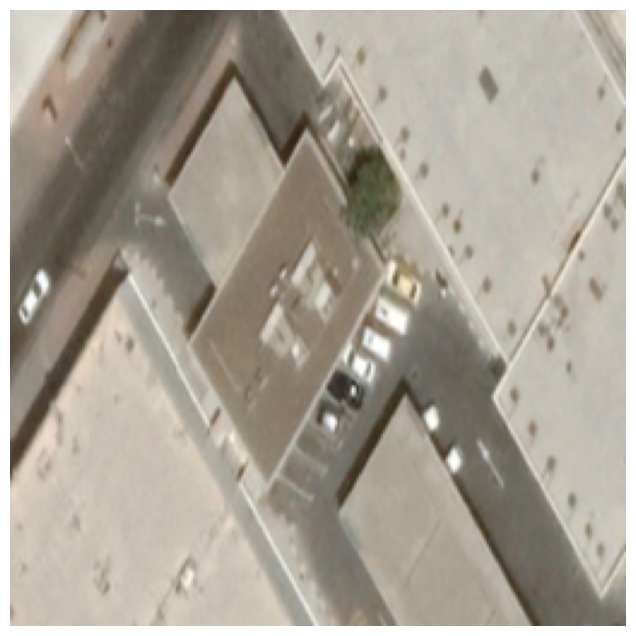

In [7]:
show_tensor_images(img[10])

#### Blocks

In [8]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, input_channels=3, hidden_dim=64):
        super(Generator, self).__init__()
        self.z_dim = z_dim
        
        self.gen = nn.Sequential(
            self.generator_block(z_dim, hidden_dim * 32, stride=1, padding=0),  
            self.generator_block(hidden_dim * 32, hidden_dim * 16), 
            self.generator_block(hidden_dim * 16, hidden_dim * 8),  
            self.generator_block(hidden_dim * 8, hidden_dim * 4),  
            self.generator_block(hidden_dim * 4, hidden_dim * 2),  
            self.generator_block(hidden_dim * 2, hidden_dim), 
            self.generator_block(hidden_dim, input_channels, final_layer=True) 
        )
        
    def generator_block(self, input_channels, output_channels, kernel_size=4, stride=2, padding=1, final_layer=False): 
        if not final_layer:
            return nn.Sequential(
                nn.ConvTranspose2d(input_channels, output_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
                nn.BatchNorm2d(output_channels),
                nn.ReLU(inplace=True)
            )
        else: 
            return nn.Sequential(
                nn.ConvTranspose2d(input_channels, output_channels, kernel_size=kernel_size, stride=stride, padding=padding),
                nn.Tanh()
            )
        
    def forward(self, noise):
        return self.gen(noise.view(len(noise), self.z_dim, 1, 1))
    
    def get_gen(self):
        return self.gen

In [9]:
def get_noise(n_samples, z_dim, device='cpu'): 
    return torch.randn(n_samples, z_dim, device=device)

In [10]:
class Discriminator(nn.Module):
    def __init__(self, input_channels=3, hidden_dim=64):
        super(Discriminator, self).__init__()
        self.disc = nn.Sequential(
            self.discriminator_block(input_channels, hidden_dim),
            self.discriminator_block(hidden_dim, hidden_dim * 2),
            self.discriminator_block(hidden_dim * 2, hidden_dim * 4),
            self.discriminator_block(hidden_dim * 4, hidden_dim * 8),
            self.discriminator_block(hidden_dim * 8, hidden_dim * 16),
            self.discriminator_block(hidden_dim * 16, hidden_dim * 32),
            self.discriminator_block(hidden_dim * 32, 1, stride=1, final_layer=True)
        )
        
    def discriminator_block(self, input_channels, output_channels, kernel_size=4, stride=2, padding=1, final_layer=False):
        if not final_layer:
            return nn.Sequential(
                nn.Conv2d(input_channels, output_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
                nn.BatchNorm2d(output_channels),
                nn.LeakyReLU(0.2, inplace=True)
            )
        else:
            return nn.Sequential(
                nn.Conv2d(input_channels, output_channels, kernel_size=kernel_size, stride=stride, padding=0, bias=False)
            )

    def forward(self, image):
        disc_pred = self.disc(image)
        return disc_pred.view(-1, 1) 

    def get_disc(self):
        return self.disc

In [11]:
def weights_init(m):
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.ConvTranspose2d):
        torch.nn.init.normal_(m.weight, 0.0, 0.02)
    if isinstance(m, nn.BatchNorm2d):
        torch.nn.init.normal_(m.weight, 0.0, 0.02)
        torch.nn.init.constant_(m.bias, 0)

In [12]:
criterion = nn.BCEWithLogitsLoss()
n_epochs = 1000
z_dim = 100 
display_step = 100  
batch_size = 64  
lr = 0.0002
beta_1 = 0.5 
beta_2 = 0.999
device='cuda'

gen = Generator(z_dim).to(device)
gen_opt = torch.optim.Adam(gen.parameters(), lr=lr, betas=(beta_1, beta_2))

disc = Discriminator().to(device)
disc_opt = torch.optim.Adam(disc.parameters(), lr=lr, betas=(beta_1, beta_2))

gen = gen.apply(weights_init)
disc = disc.apply(weights_init)

In [13]:
def display_tensor_images(image_tensor, num_images=25, size=(3, 256, 256)):
    # Rescale image tensor from [-1, 1] to [0, 1]
    image_tensor = (image_tensor + 1) / 2
    
    image_unflat = image_tensor.detach().cpu().view(-1, *size)
    image_grid = make_grid(image_unflat[:num_images], nrow=5)
    
    plt.imshow(image_grid.permute(1, 2, 0).squeeze())
    plt.axis('off')  # Optional: Hide axis
    plt.show()


In [14]:
def save_checkpoints(gen, disc, gen_opt, disc_opt, gen_loss, disc_loss, path): 
    torch.save({
        'gen_state_dict': gen.state_dict(),
        'disc_state_dict': disc.state_dict(),
        'gen_opt_state_dict': gen_opt.state_dict(),
        'disc_opt_state_dict': disc_opt.state_dict(),
        'gen_loss': gen_loss,
        'disc_loss': disc_loss
    }, path)

 29%|████████████████████████                                                            | 2/7 [00:27<01:05, 13.16s/it]

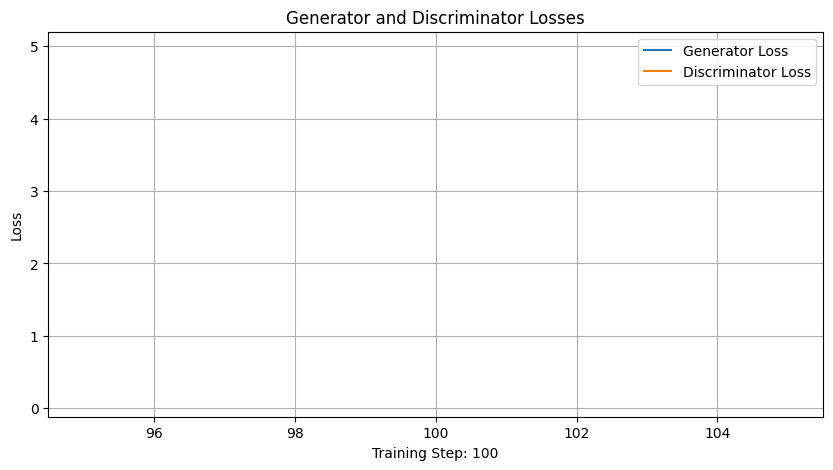

Step 100: Generator loss: 4.959438812732697, discriminator loss: 0.1251734493393451


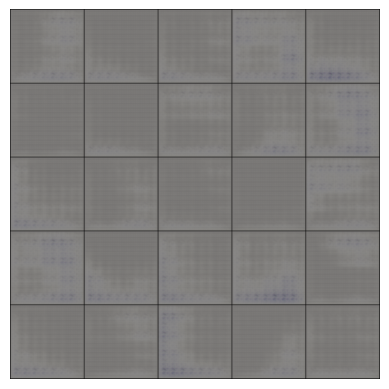

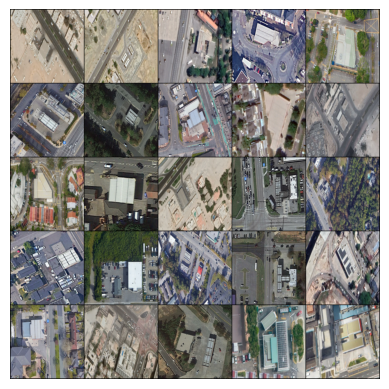

 57%|████████████████████████████████████████████████                                    | 4/7 [00:46<00:34, 11.34s/it]

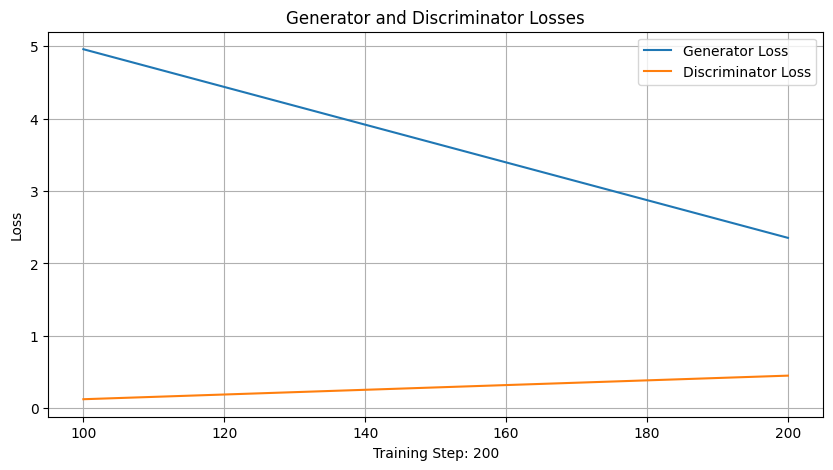

Step 200: Generator loss: 2.354009488224983, discriminator loss: 0.45089017681777477


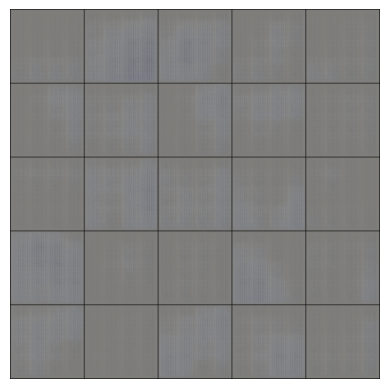

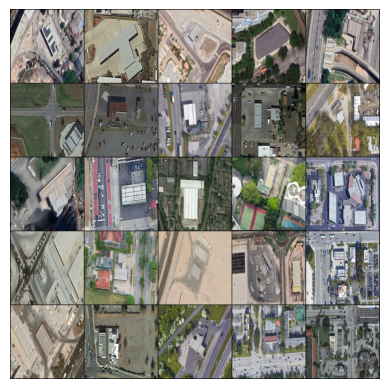

 86%|████████████████████████████████████████████████████████████████████████            | 6/7 [01:13<00:11, 11.92s/it]

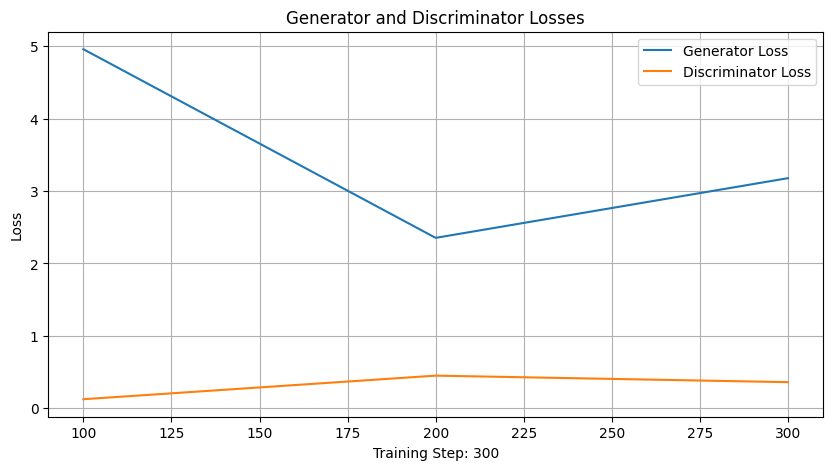

Step 300: Generator loss: 3.178154821395874, discriminator loss: 0.3608293627947569


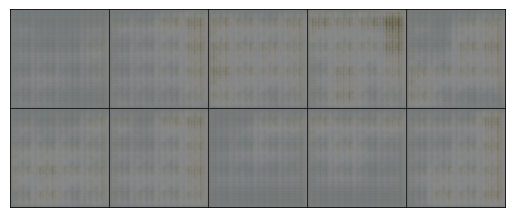

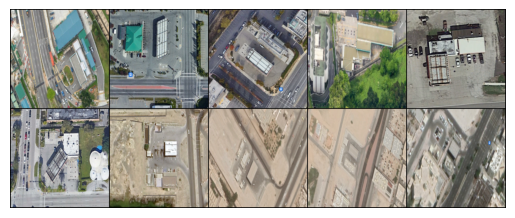

 14%|████████████                                                                        | 1/7 [00:14<01:27, 14.52s/it]

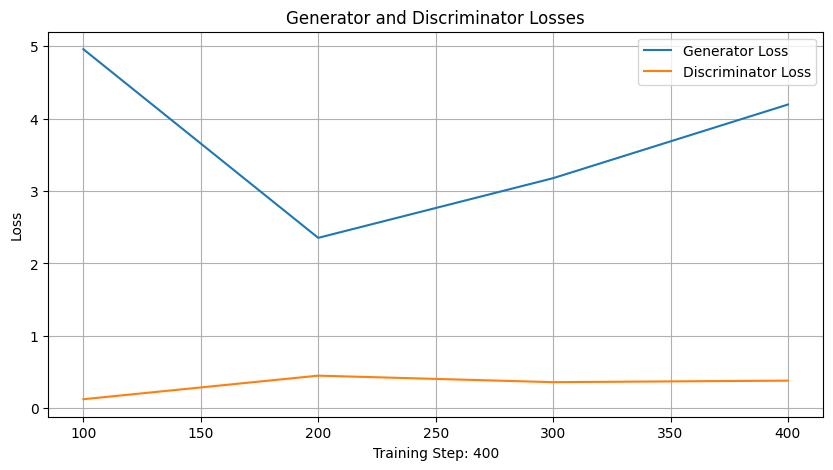

Step 400: Generator loss: 4.195479497909546, discriminator loss: 0.38195160157978536


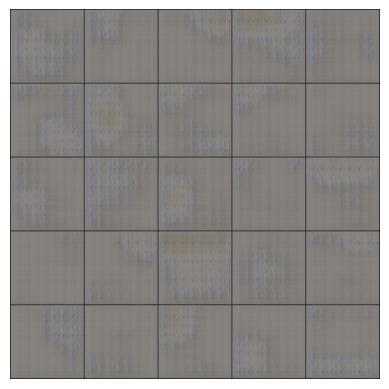

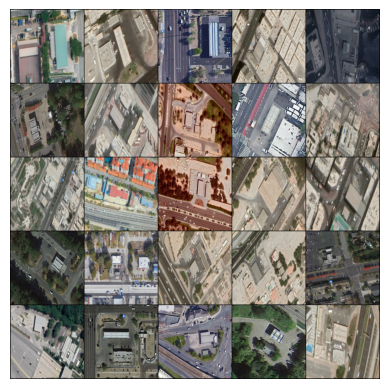

 43%|████████████████████████████████████                                                | 3/7 [00:39<00:51, 12.78s/it]

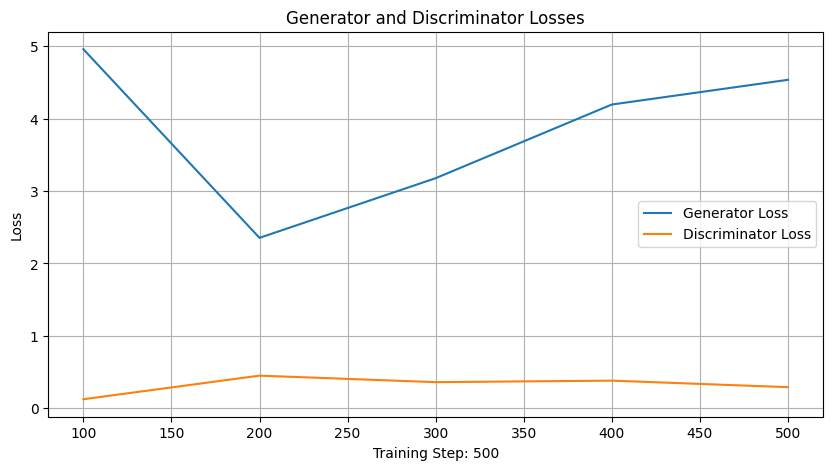

Step 500: Generator loss: 4.5369978320598605, discriminator loss: 0.29160990975797174


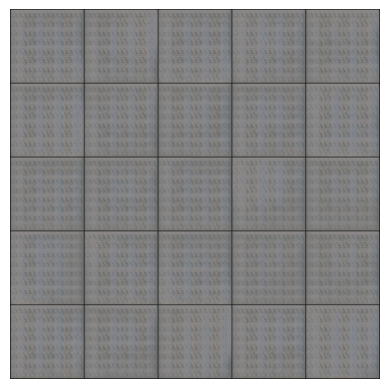

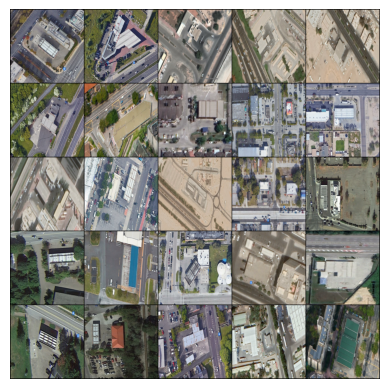

 71%|████████████████████████████████████████████████████████████                        | 5/7 [00:55<00:21, 10.67s/it]

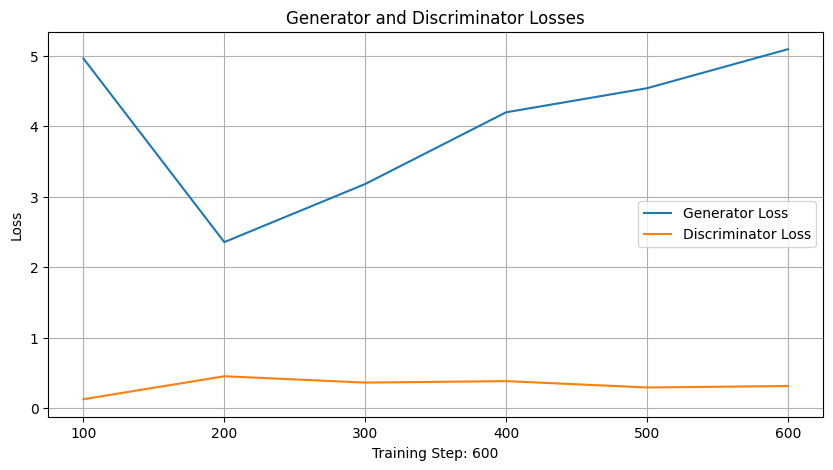

Step 600: Generator loss: 5.090175929069519, discriminator loss: 0.3125612449645996


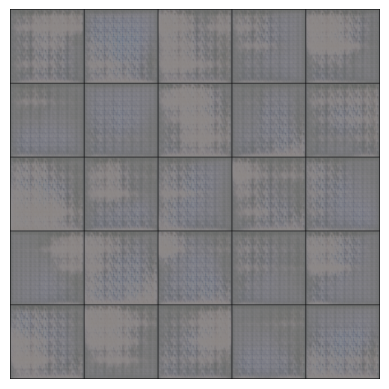

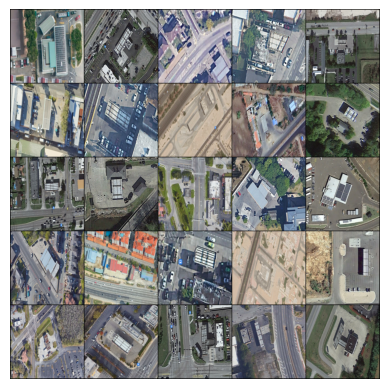

  0%|                                                                                            | 0/7 [00:00<?, ?it/s]

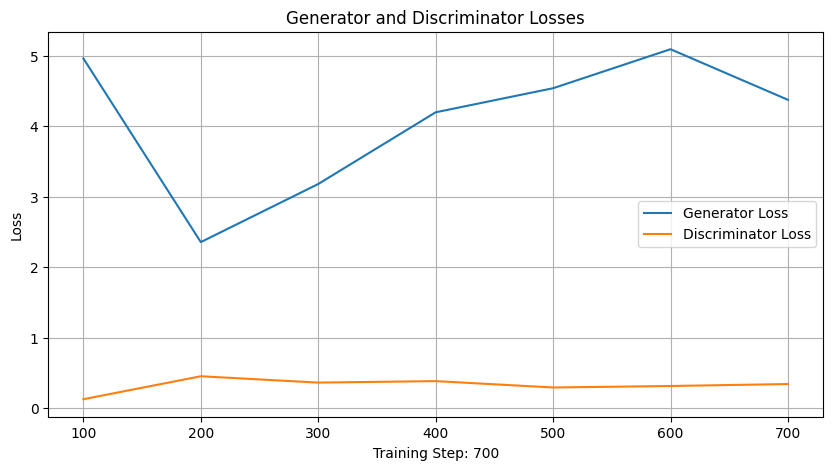

Step 700: Generator loss: 4.372490977048874, discriminator loss: 0.3404692886769772


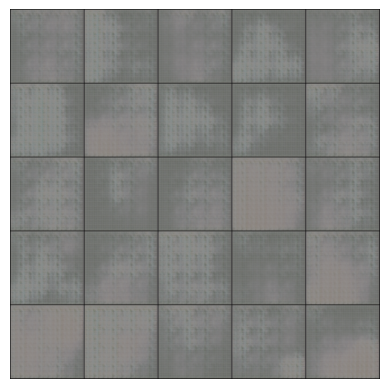

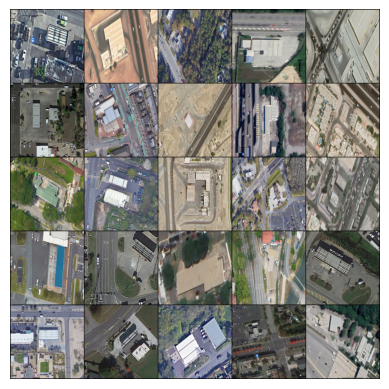

 29%|████████████████████████                                                            | 2/7 [00:25<01:04, 12.98s/it]

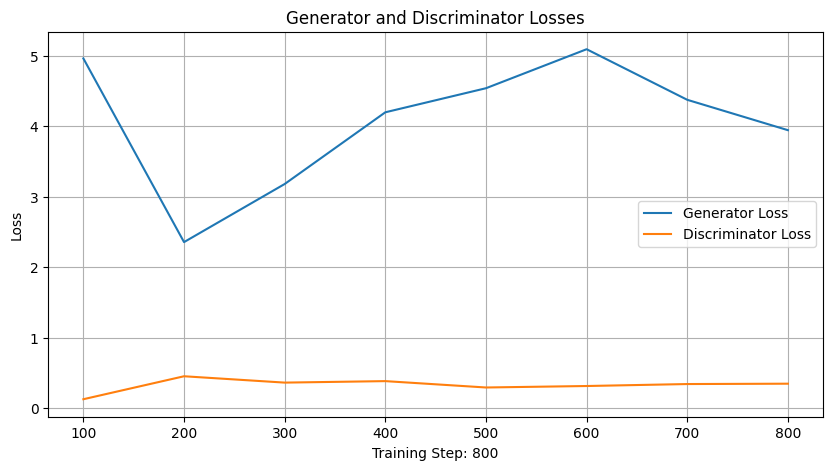

Step 800: Generator loss: 3.9417605638504027, discriminator loss: 0.34545491077005863


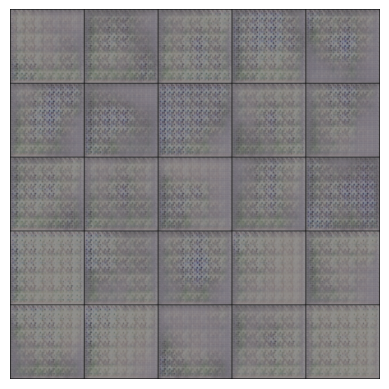

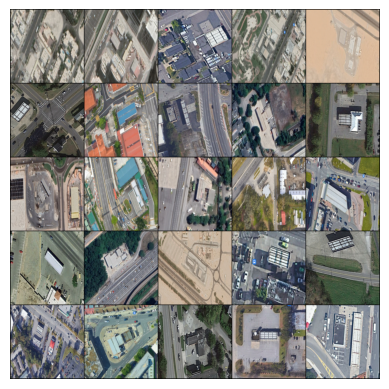

 57%|████████████████████████████████████████████████                                    | 4/7 [00:43<00:32, 10.73s/it]

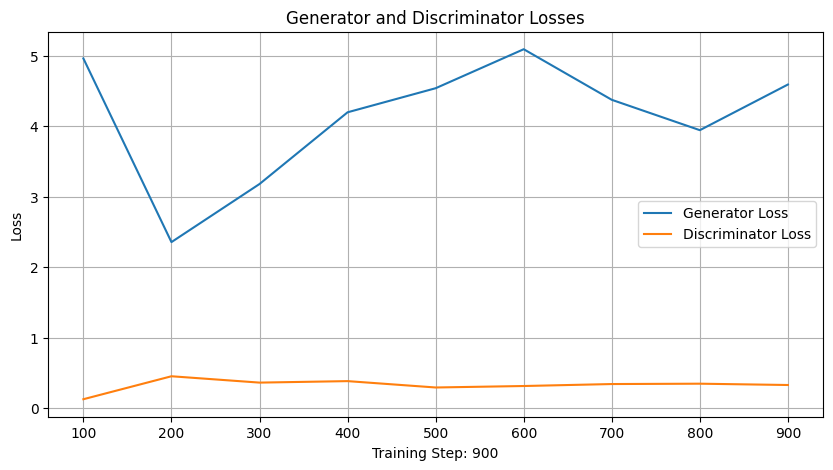

Step 900: Generator loss: 4.589519093036651, discriminator loss: 0.3268380132690072


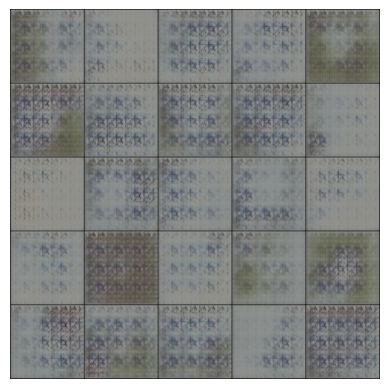

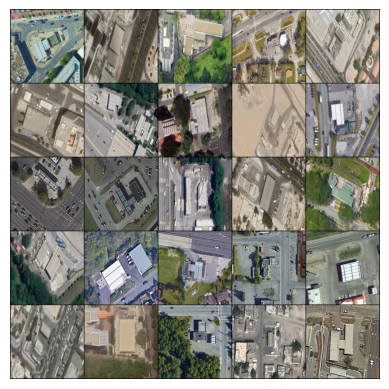

 86%|████████████████████████████████████████████████████████████████████████            | 6/7 [01:14<00:11, 11.90s/it]

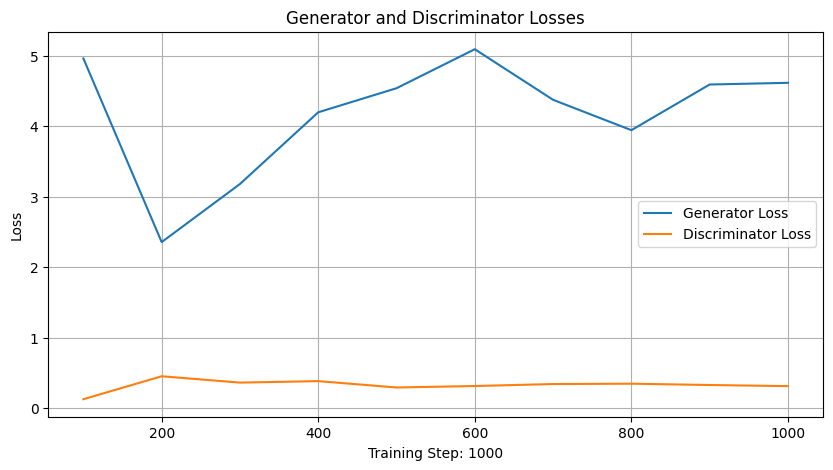

Step 1000: Generator loss: 4.6135500156879425, discriminator loss: 0.31095107227563856


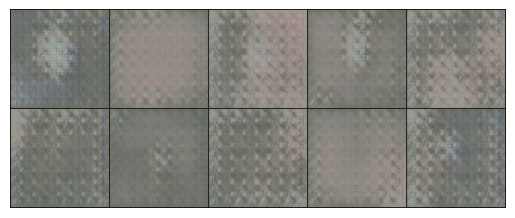

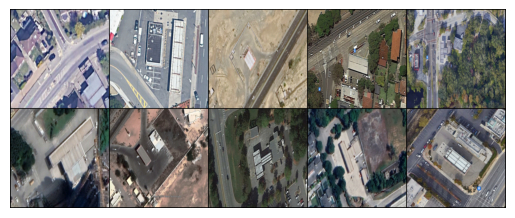

 14%|████████████                                                                        | 1/7 [00:17<01:42, 17.13s/it]

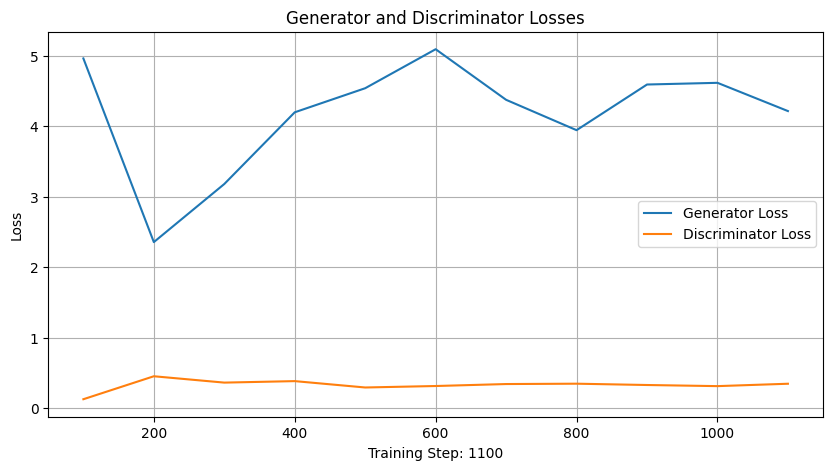

Step 1100: Generator loss: 4.212912755012512, discriminator loss: 0.3447732208669186


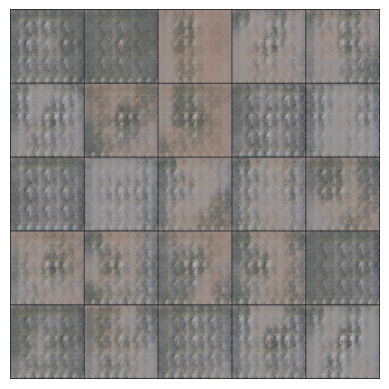

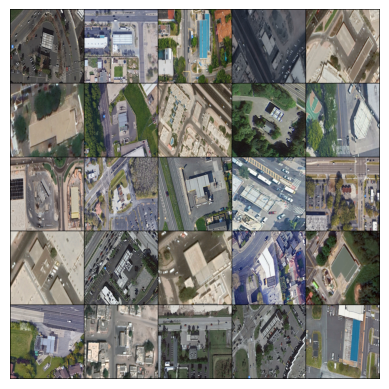

 43%|████████████████████████████████████                                                | 3/7 [00:31<00:40, 10.16s/it]

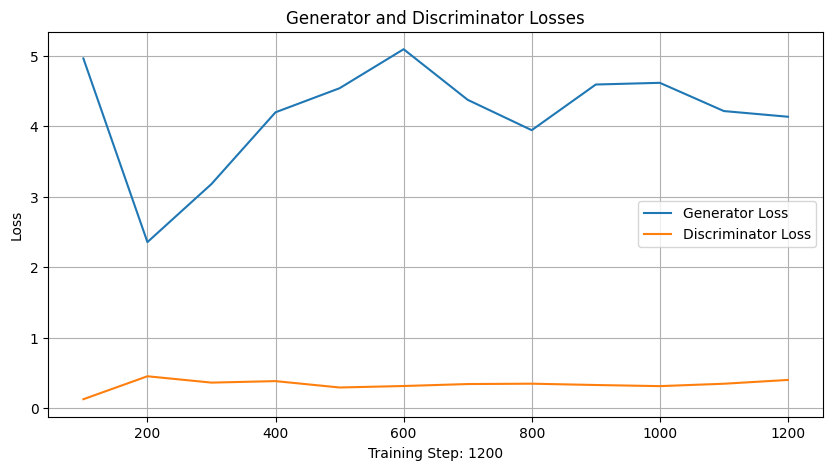

Step 1200: Generator loss: 4.132425522208214, discriminator loss: 0.3986549091339111


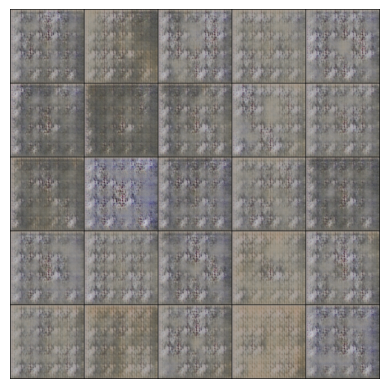

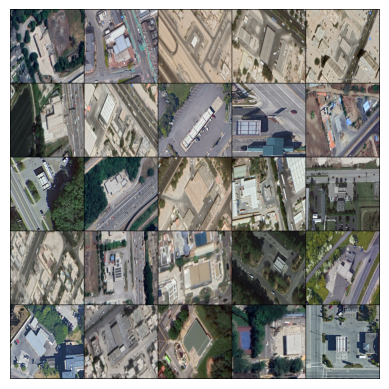

 71%|████████████████████████████████████████████████████████████                        | 5/7 [00:54<00:21, 10.56s/it]

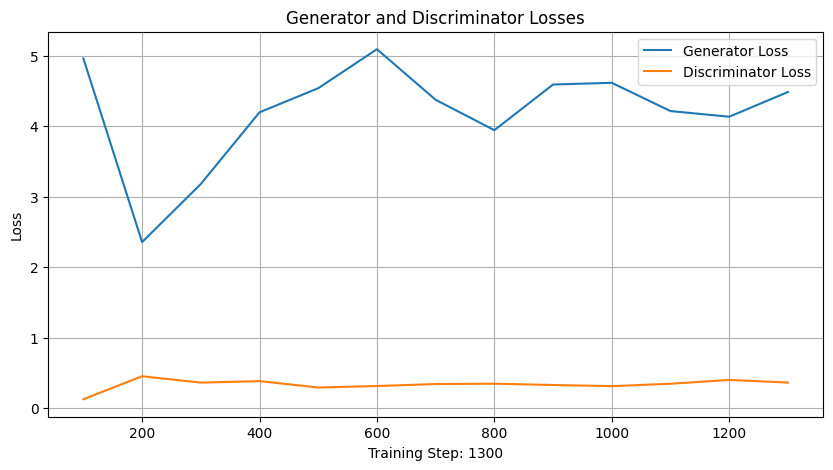

Step 1300: Generator loss: 4.482927004098892, discriminator loss: 0.361620030477643


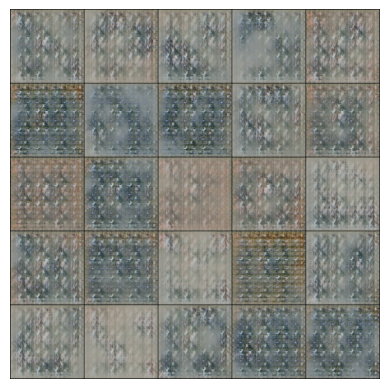

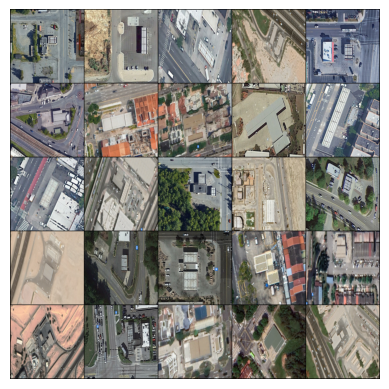

  0%|                                                                                            | 0/7 [00:00<?, ?it/s]

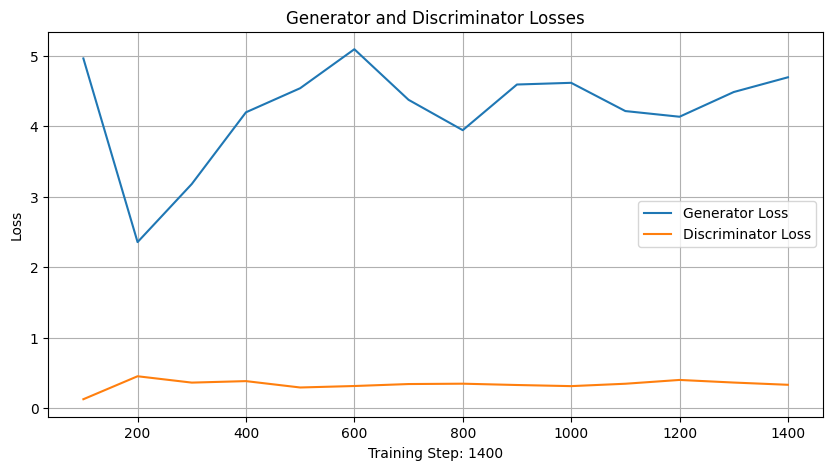

Step 1400: Generator loss: 4.692010673880577, discriminator loss: 0.3299438300728798


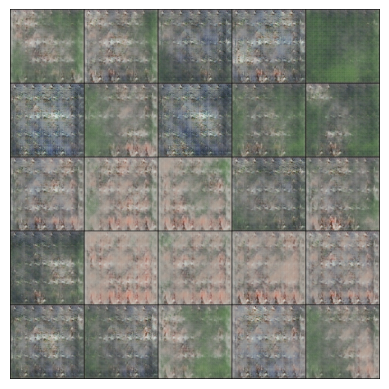

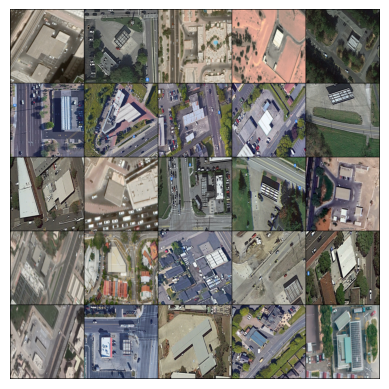

 29%|████████████████████████                                                            | 2/7 [00:27<01:05, 13.17s/it]

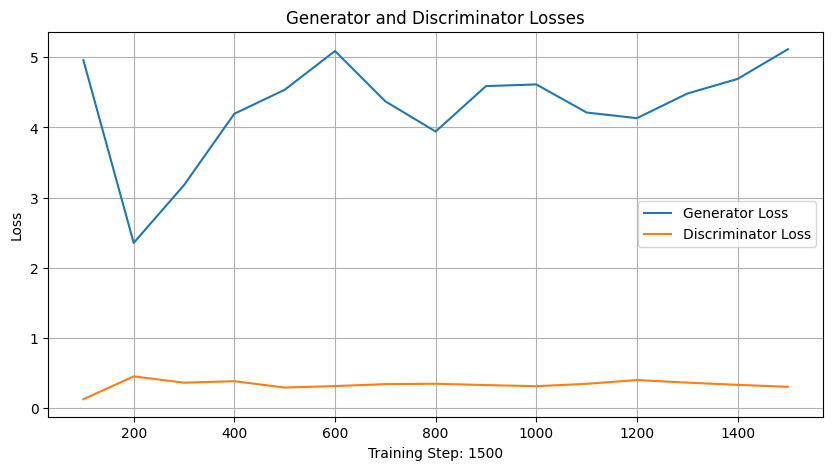

Step 1500: Generator loss: 5.11546856045723, discriminator loss: 0.30194695249199865


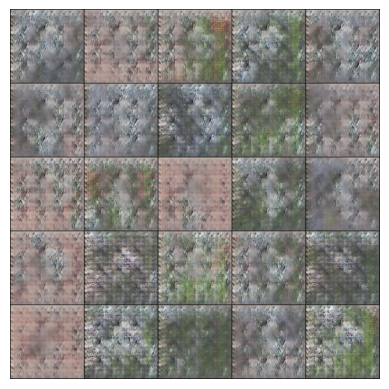

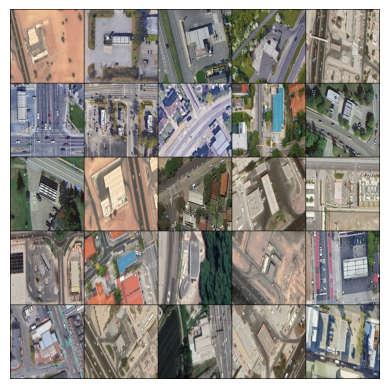

 57%|████████████████████████████████████████████████                                    | 4/7 [00:51<00:36, 12.32s/it]

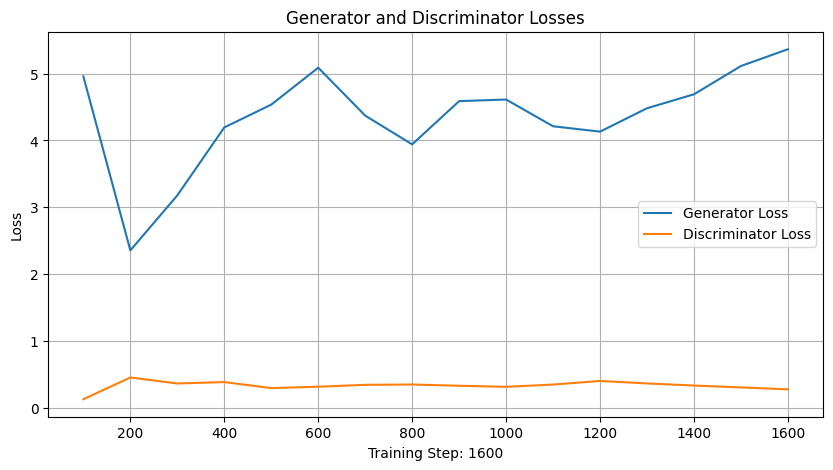

Step 1600: Generator loss: 5.36683109998703, discriminator loss: 0.2730250948294997


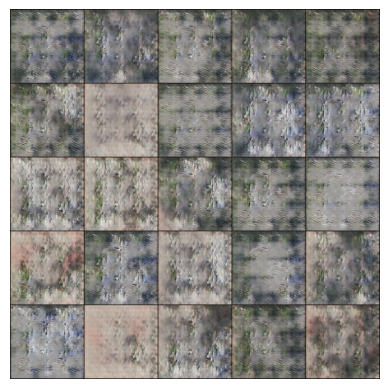

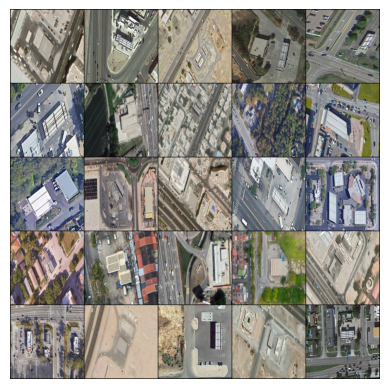

 86%|████████████████████████████████████████████████████████████████████████            | 6/7 [01:07<00:11, 11.50s/it]

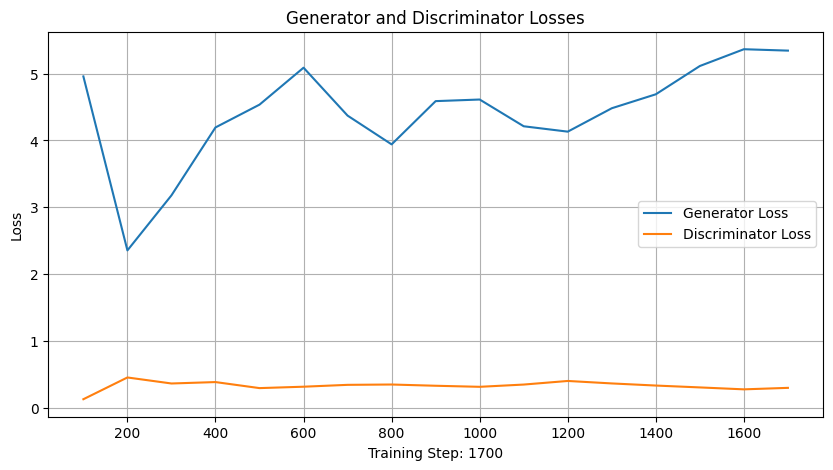

Step 1700: Generator loss: 5.345854024887085, discriminator loss: 0.29538793064653873


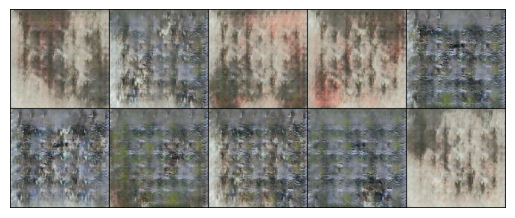

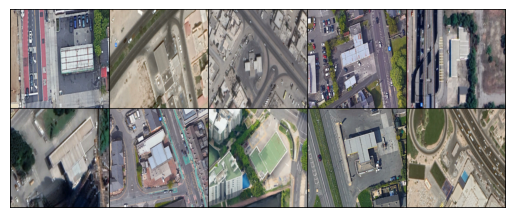

 14%|████████████                                                                        | 1/7 [00:15<01:30, 15.08s/it]

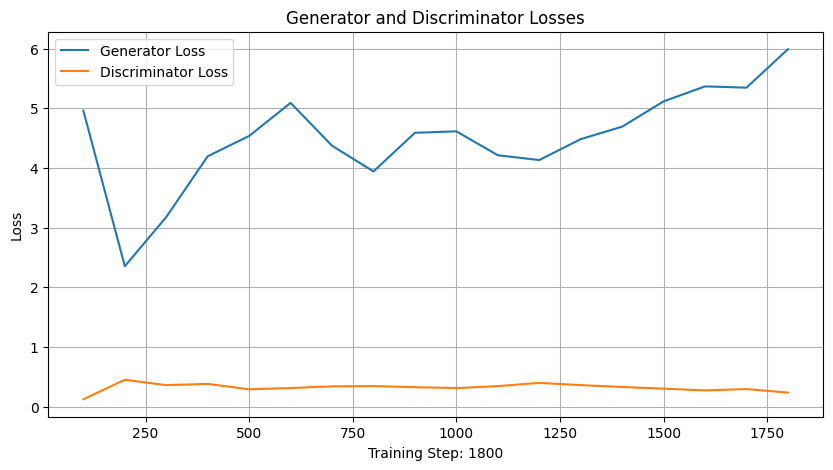

Step 1800: Generator loss: 5.989538681507111, discriminator loss: 0.23598019994795322


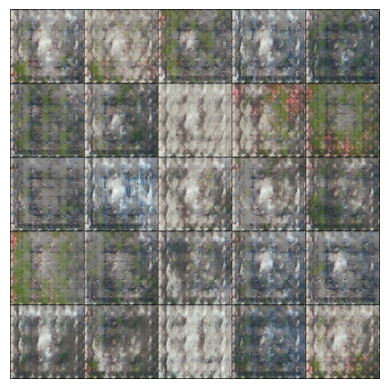

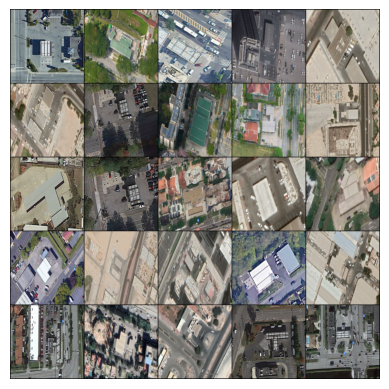

 43%|████████████████████████████████████                                                | 3/7 [00:36<00:47, 11.99s/it]

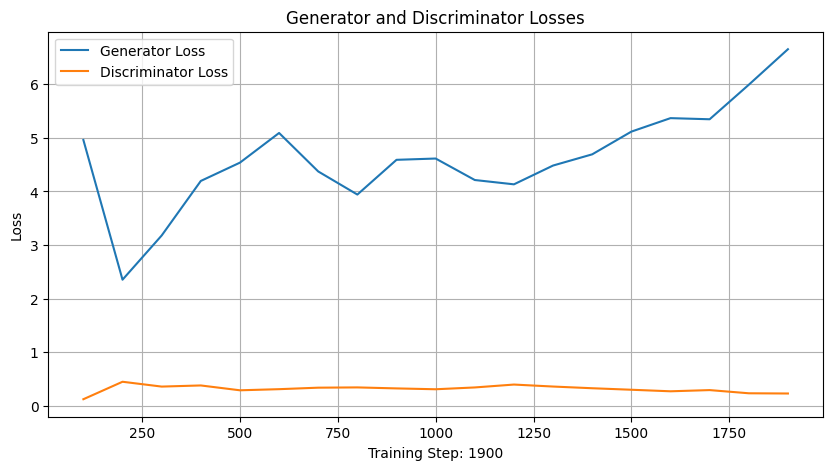

Step 1900: Generator loss: 6.651981546878814, discriminator loss: 0.23184147577732803


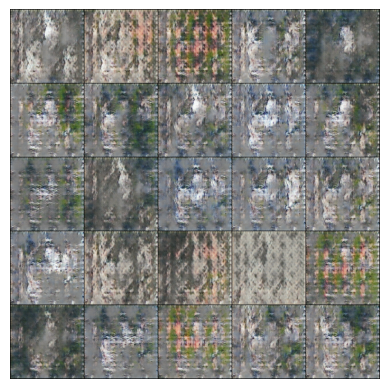

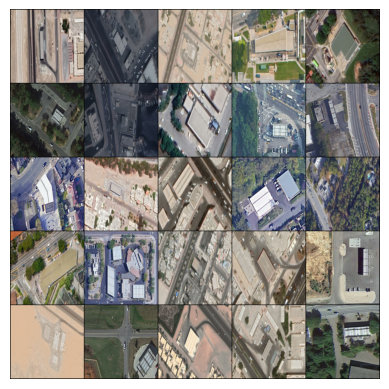

 71%|████████████████████████████████████████████████████████████                        | 5/7 [01:06<00:26, 13.04s/it]

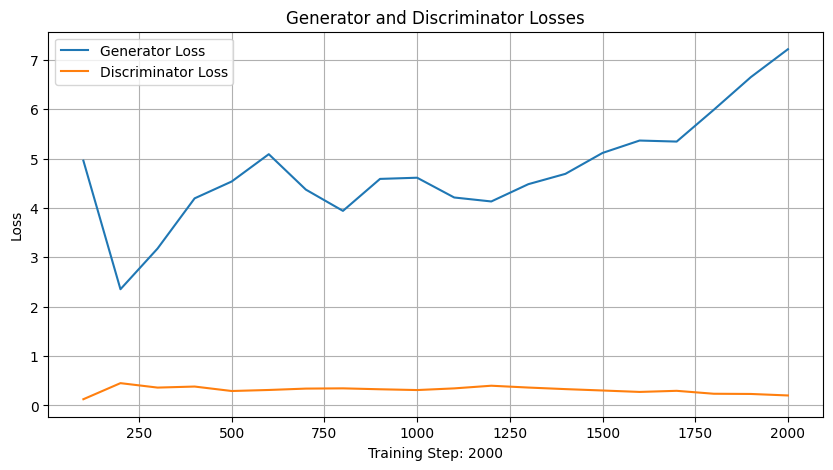

Step 2000: Generator loss: 7.217263026237488, discriminator loss: 0.20141824137419462


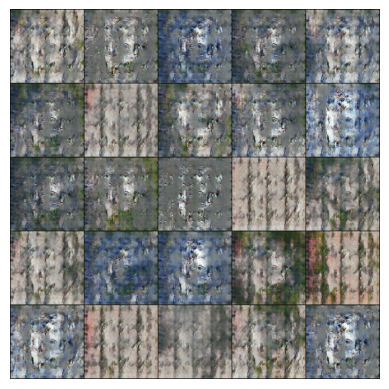

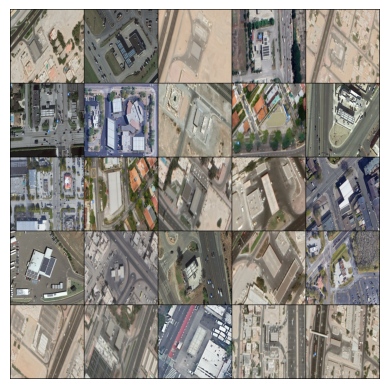

  0%|                                                                                            | 0/7 [00:00<?, ?it/s]

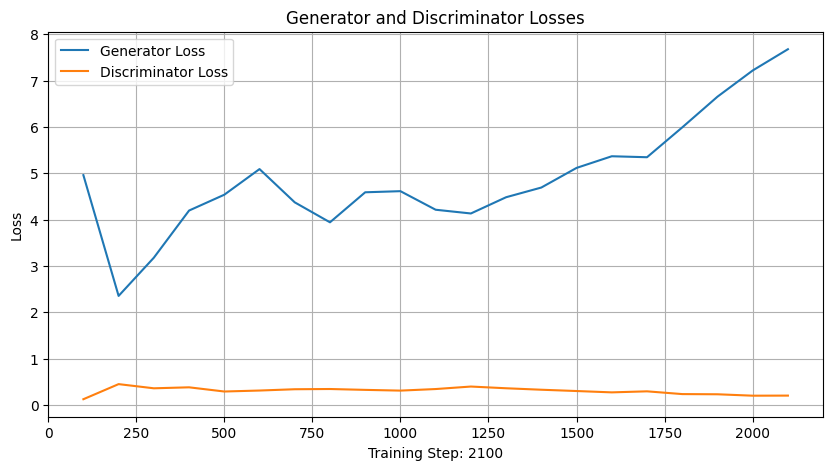

Step 2100: Generator loss: 7.675927069187164, discriminator loss: 0.20330011637881398


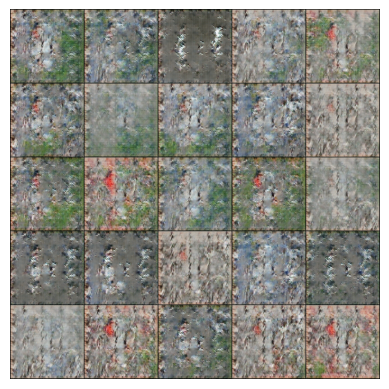

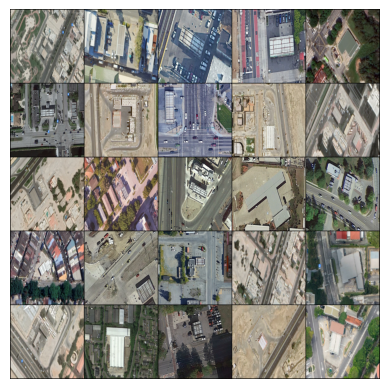

 29%|████████████████████████                                                            | 2/7 [00:26<01:05, 13.10s/it]

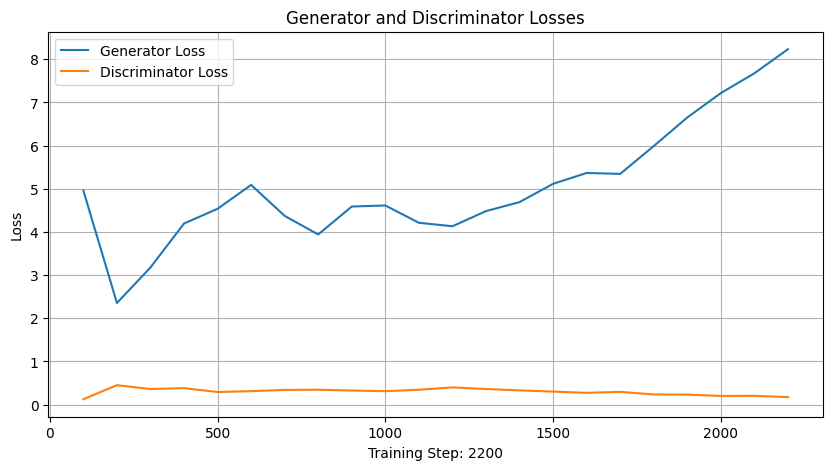

Step 2200: Generator loss: 8.233802461624146, discriminator loss: 0.17564300585538148


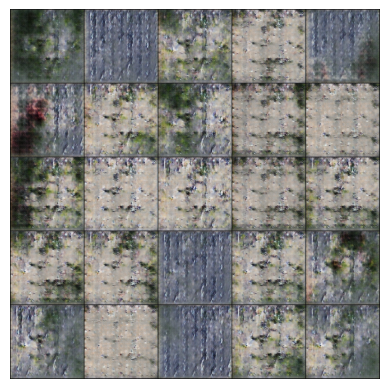

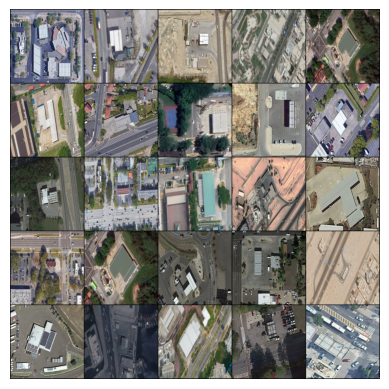

 57%|████████████████████████████████████████████████                                    | 4/7 [00:47<00:36, 12.01s/it]

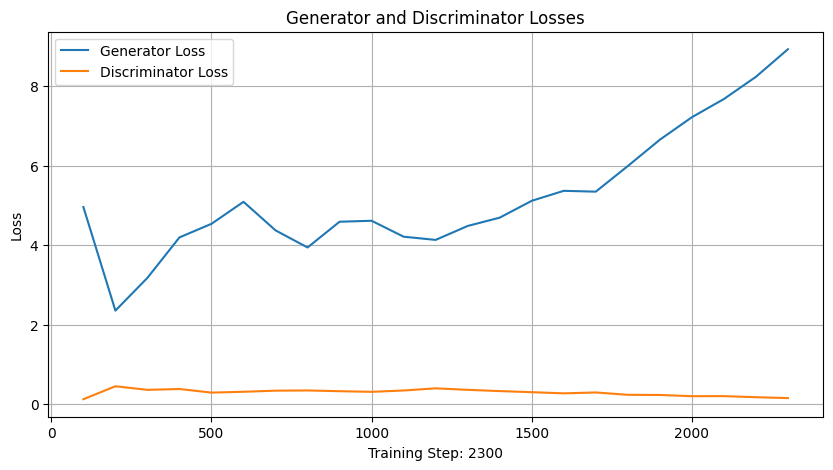

Step 2300: Generator loss: 8.928319599628448, discriminator loss: 0.1531656568683684


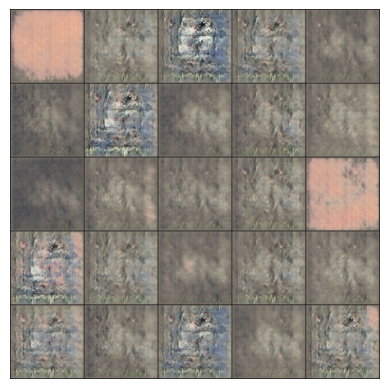

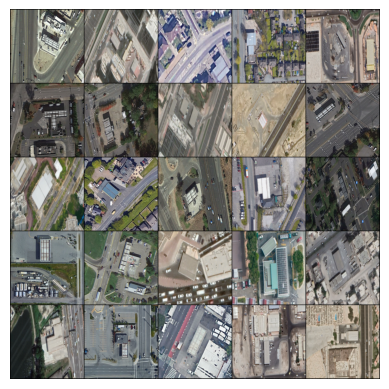

 86%|████████████████████████████████████████████████████████████████████████            | 6/7 [01:08<00:10, 11.00s/it]

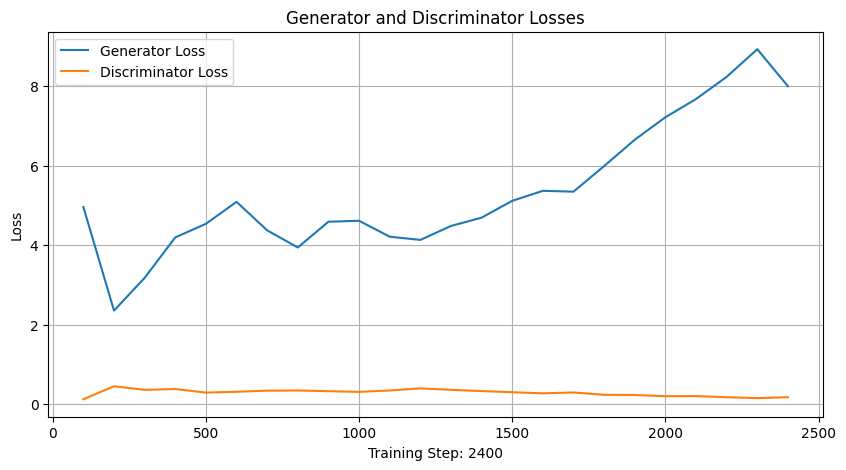

Step 2400: Generator loss: 7.997307460308075, discriminator loss: 0.17555850120261313


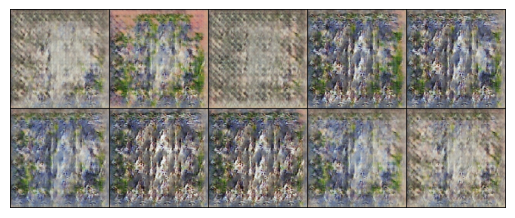

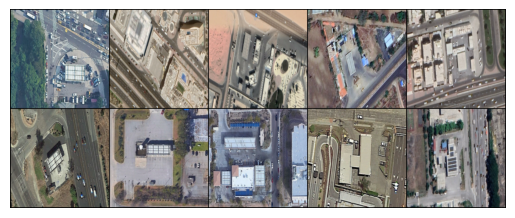

 14%|████████████                                                                        | 1/7 [00:14<01:26, 14.46s/it]

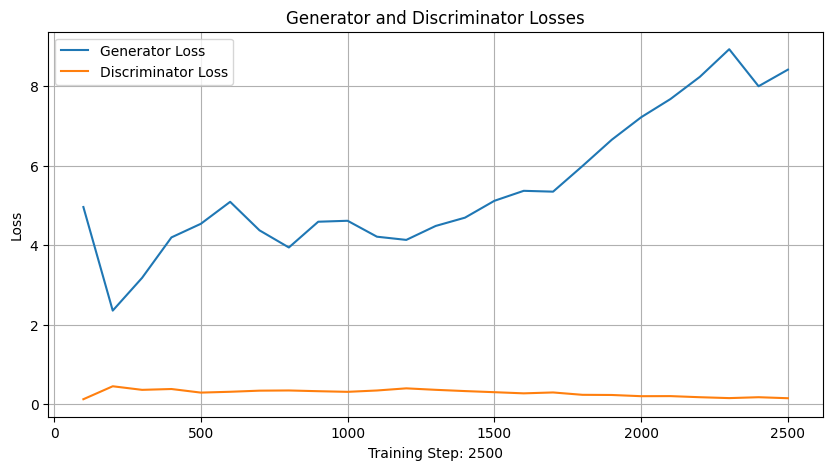

Step 2500: Generator loss: 8.414989123344421, discriminator loss: 0.15023003555368633


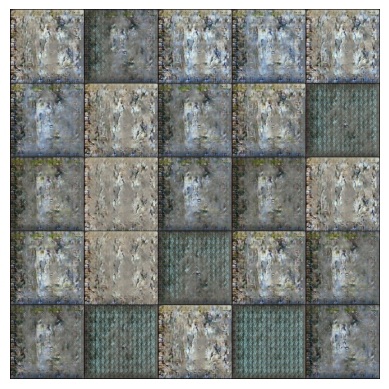

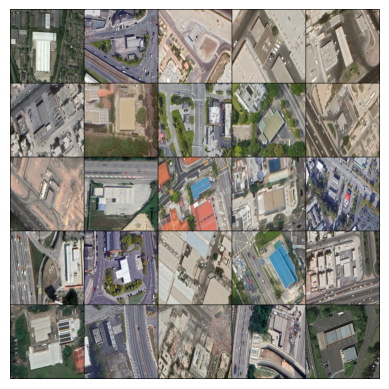

 43%|████████████████████████████████████                                                | 3/7 [00:38<00:49, 12.28s/it]

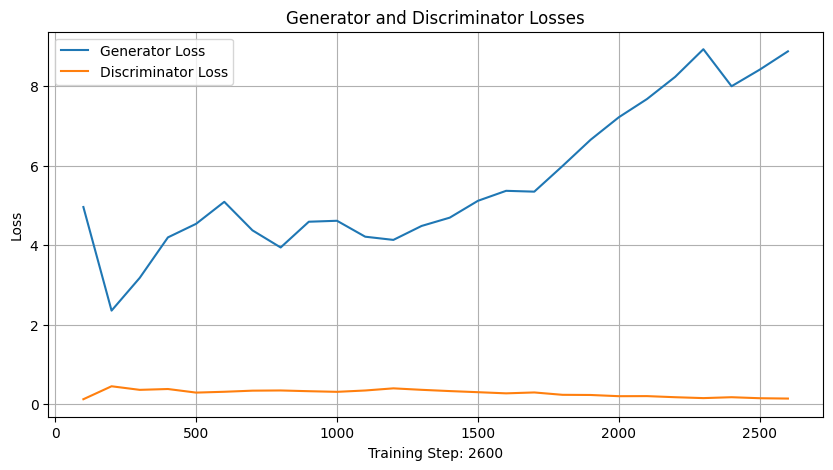

Step 2600: Generator loss: 8.875137922763825, discriminator loss: 0.14168045587372036


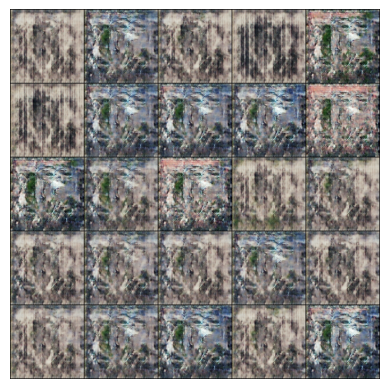

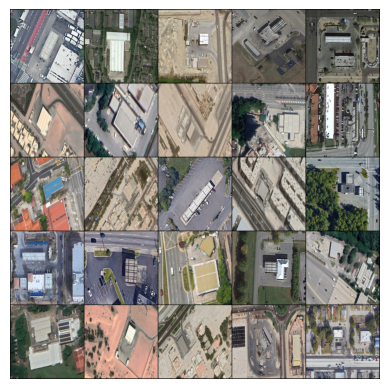

 71%|████████████████████████████████████████████████████████████                        | 5/7 [00:55<00:20, 10.24s/it]

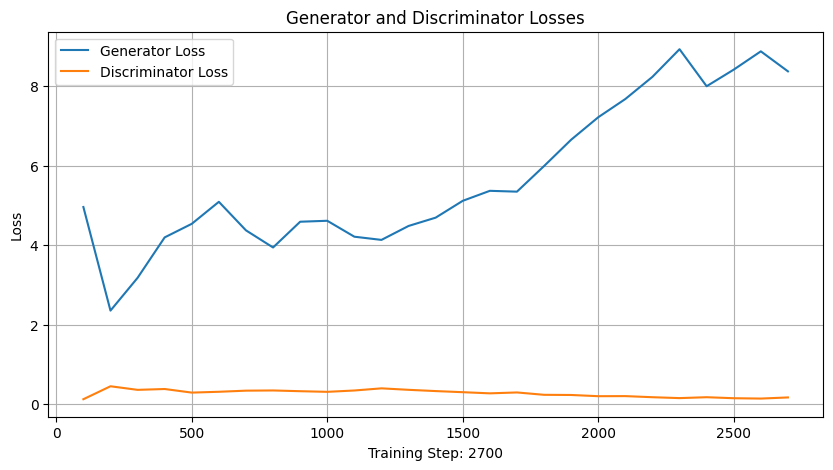

Step 2700: Generator loss: 8.37189361333847, discriminator loss: 0.16992444512434304


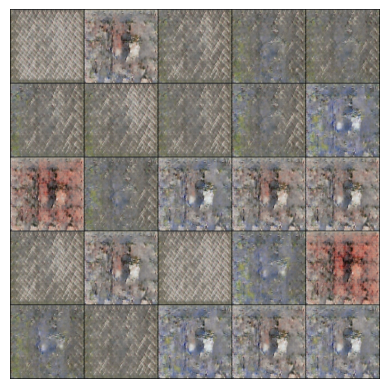

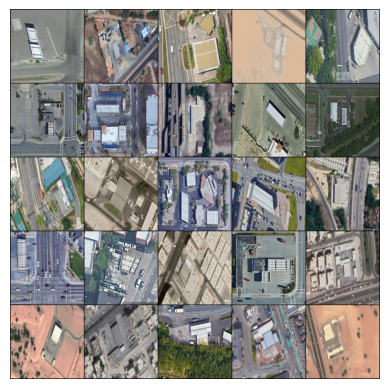

  0%|                                                                                            | 0/7 [00:00<?, ?it/s]

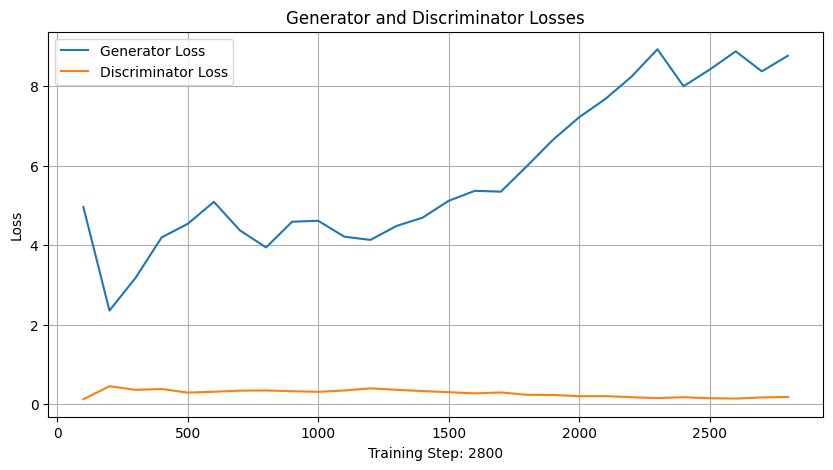

Step 2800: Generator loss: 8.765003538131714, discriminator loss: 0.1824598631868139


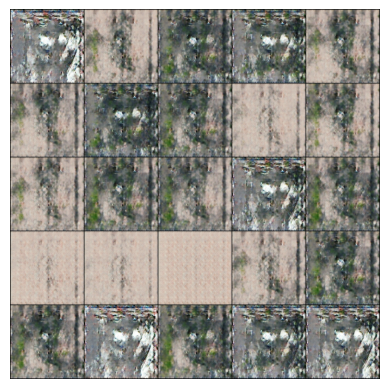

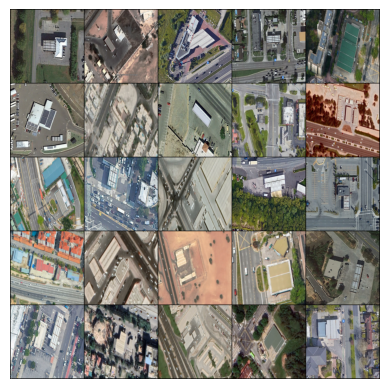

 29%|████████████████████████                                                            | 2/7 [00:28<01:11, 14.34s/it]

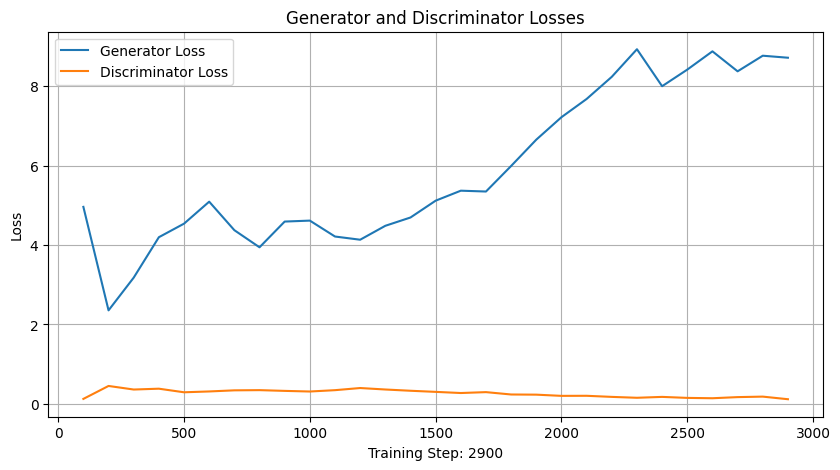

Step 2900: Generator loss: 8.714105799198151, discriminator loss: 0.11689630188047886


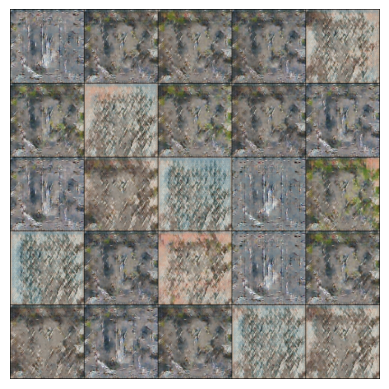

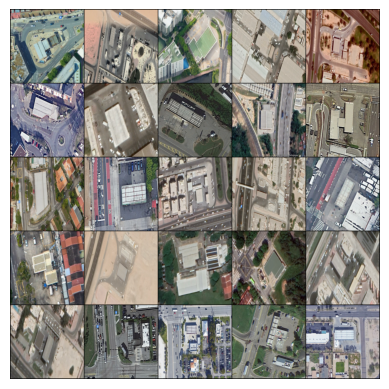

 57%|████████████████████████████████████████████████                                    | 4/7 [00:46<00:34, 11.47s/it]

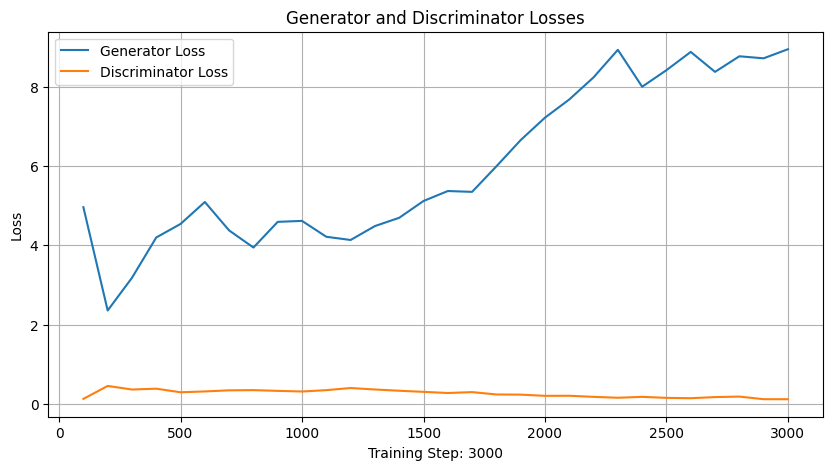

Step 3000: Generator loss: 8.943205749988556, discriminator loss: 0.11611882859375328


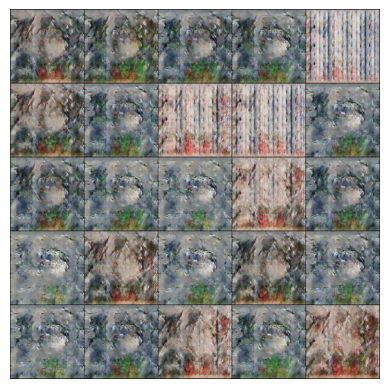

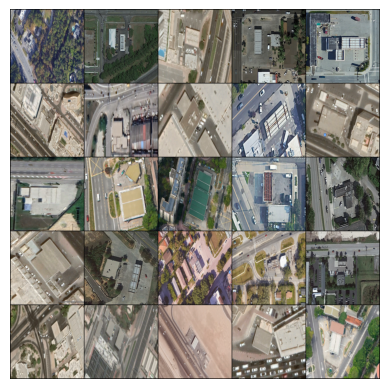

 86%|████████████████████████████████████████████████████████████████████████            | 6/7 [01:15<00:12, 12.50s/it]

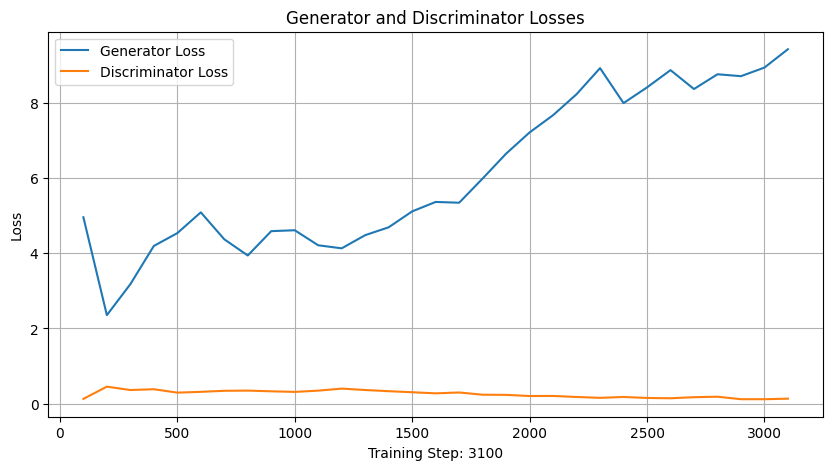

Step 3100: Generator loss: 9.431398956775665, discriminator loss: 0.13106699189636856


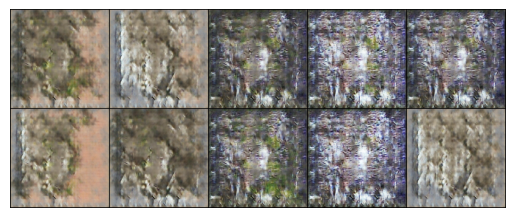

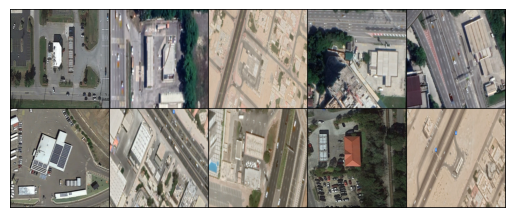

 14%|████████████                                                                        | 1/7 [00:13<01:22, 13.80s/it]

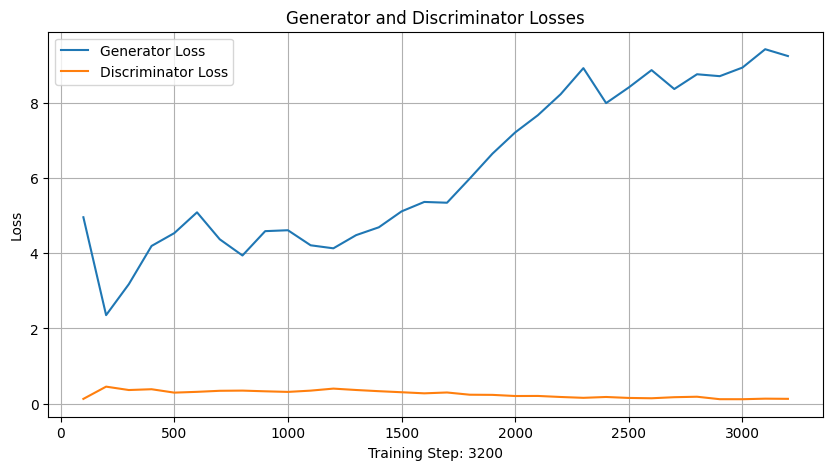

Step 3200: Generator loss: 9.249817737340926, discriminator loss: 0.12634946165024302


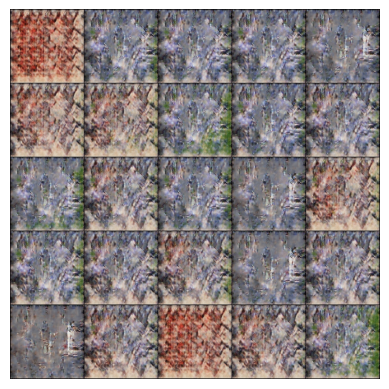

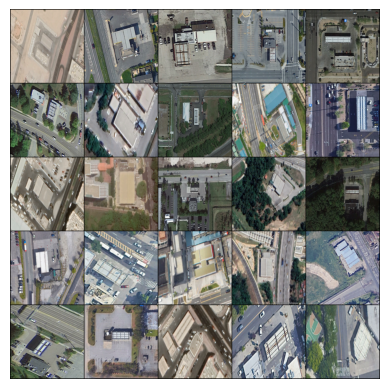

 43%|████████████████████████████████████                                                | 3/7 [00:34<00:42, 10.54s/it]

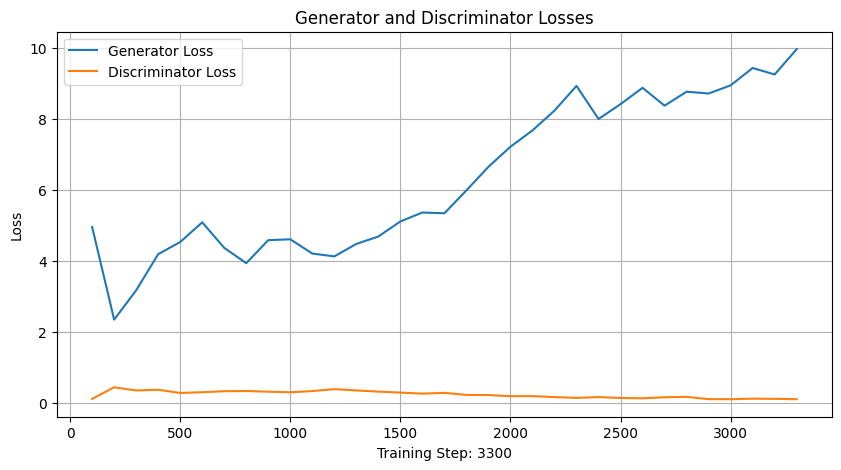

Step 3300: Generator loss: 9.959777240436525, discriminator loss: 0.1153296634927392


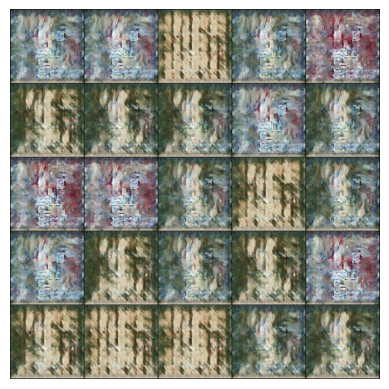

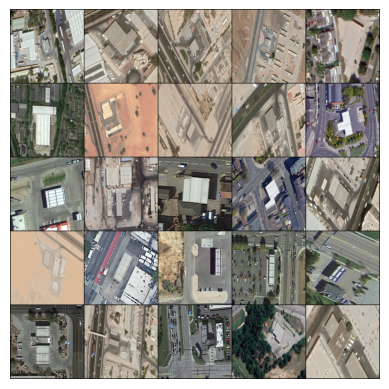

 71%|████████████████████████████████████████████████████████████                        | 5/7 [00:55<00:23, 11.52s/it]

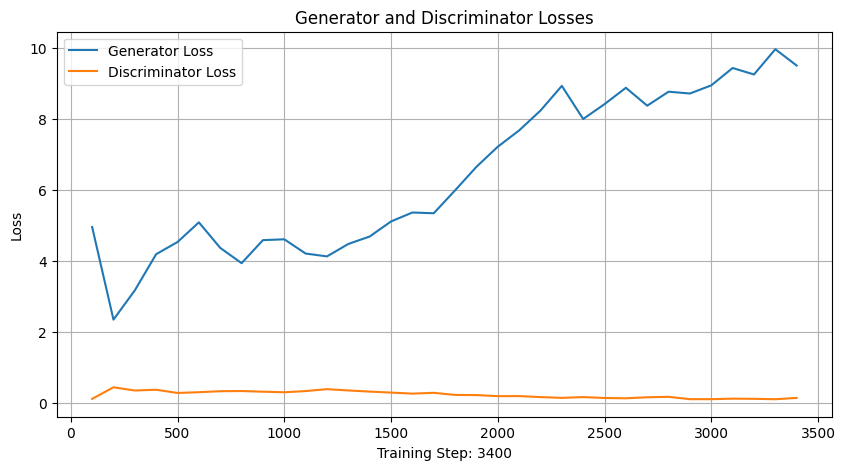

Step 3400: Generator loss: 9.500428236722946, discriminator loss: 0.15208486322313547


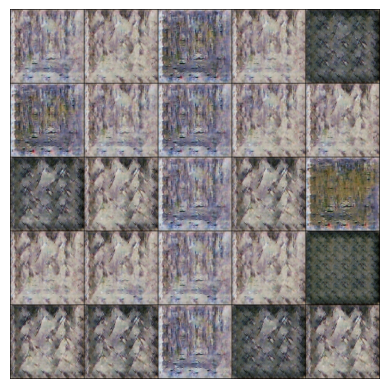

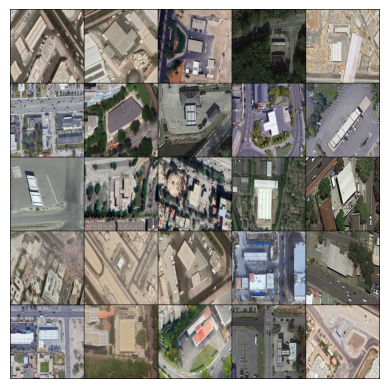

  0%|                                                                                            | 0/7 [00:00<?, ?it/s]

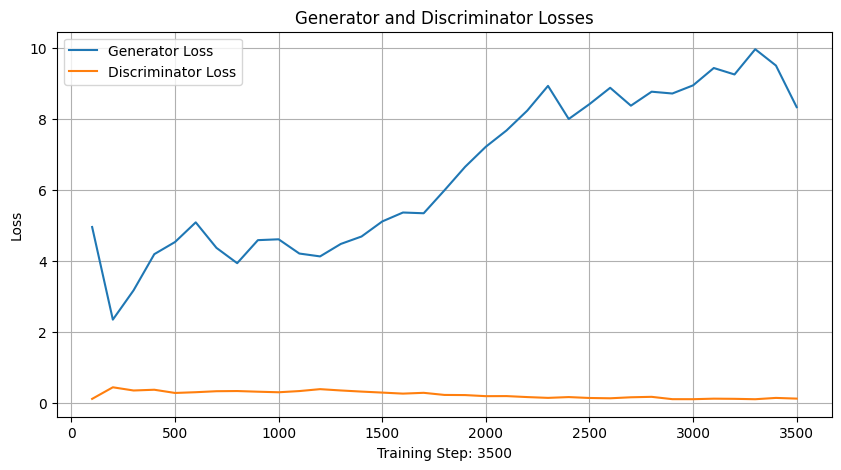

Step 3500: Generator loss: 8.330302648544311, discriminator loss: 0.1324771180166863


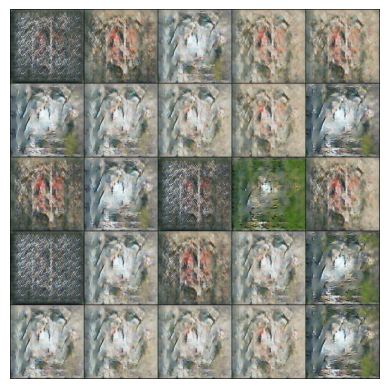

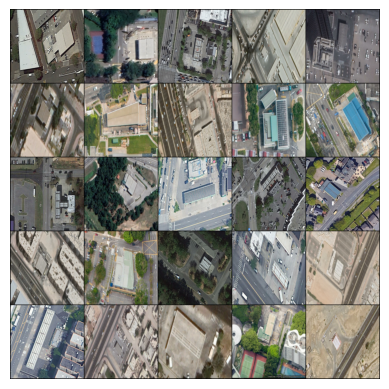

 29%|████████████████████████                                                            | 2/7 [00:29<01:13, 14.63s/it]

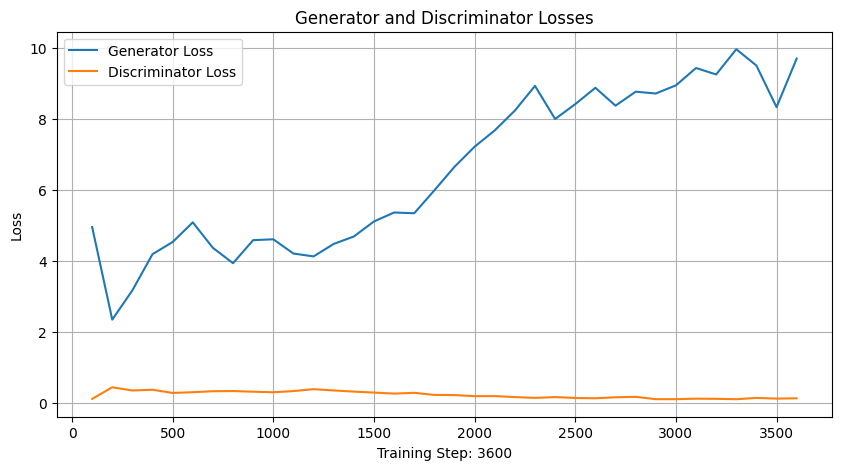

Step 3600: Generator loss: 9.696521182060241, discriminator loss: 0.14125496395863593


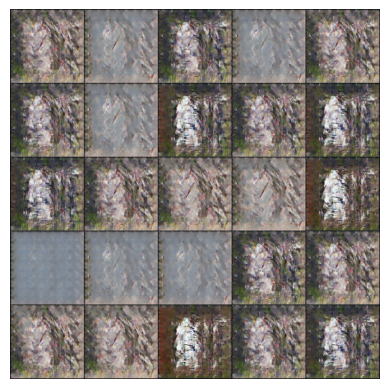

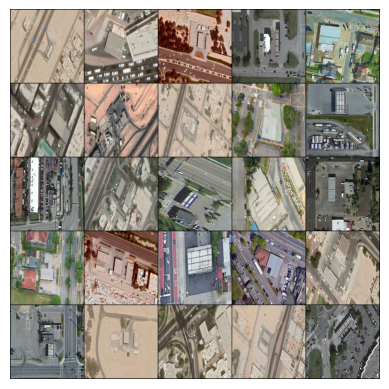

 57%|████████████████████████████████████████████████                                    | 4/7 [00:45<00:35, 11.93s/it]

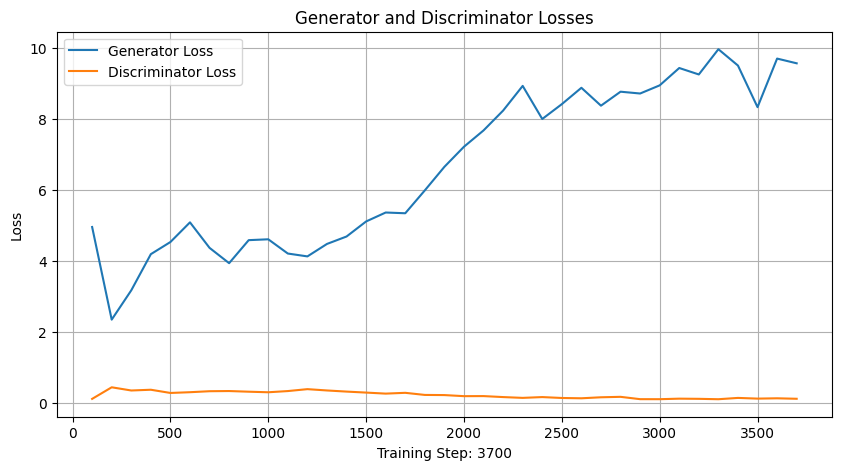

Step 3700: Generator loss: 9.563569046258927, discriminator loss: 0.12781975187710487


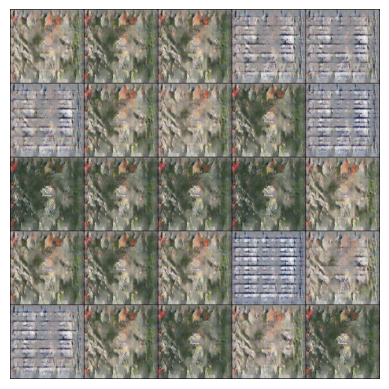

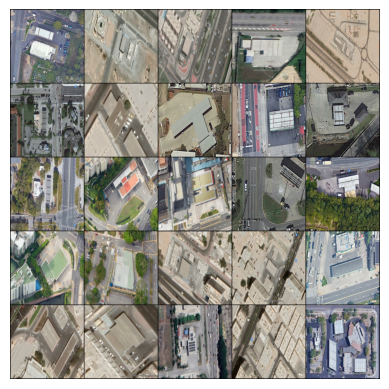

 86%|████████████████████████████████████████████████████████████████████████            | 6/7 [01:13<00:11, 11.52s/it]

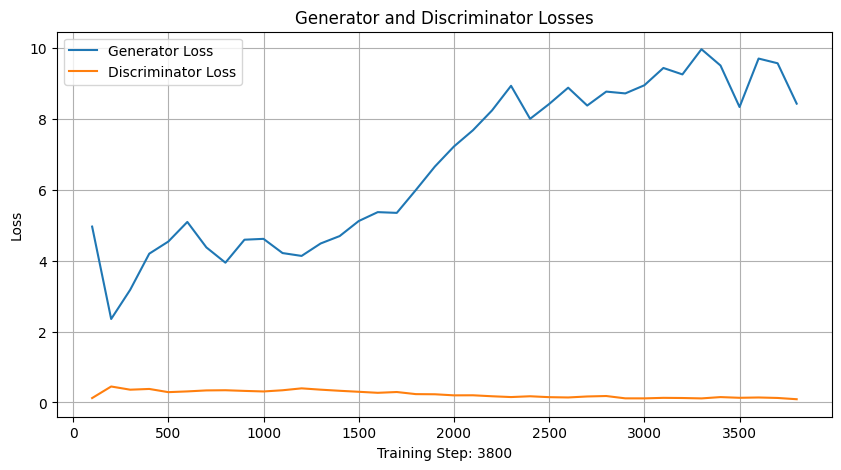

Step 3800: Generator loss: 8.425560559034347, discriminator loss: 0.09222978407982736


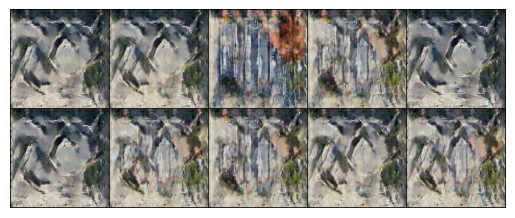

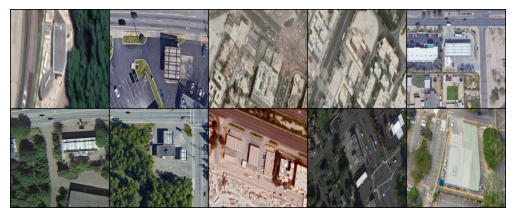

 14%|████████████                                                                        | 1/7 [00:11<01:08, 11.41s/it]

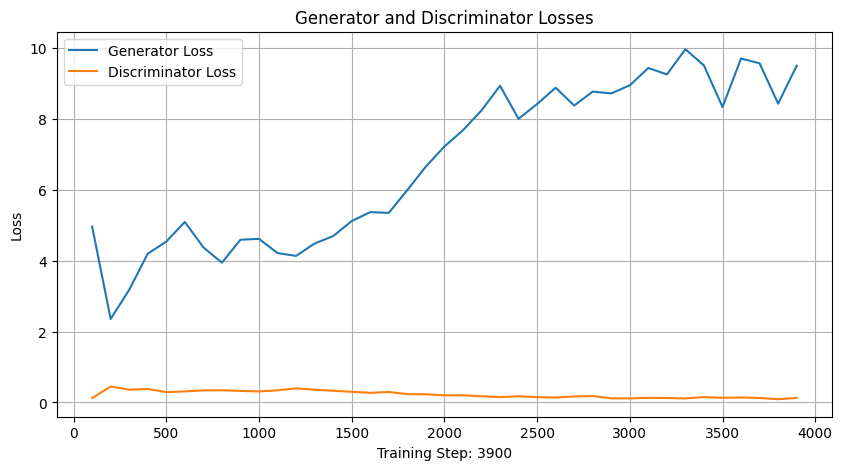

Step 3900: Generator loss: 9.493905091285706, discriminator loss: 0.129264417628292


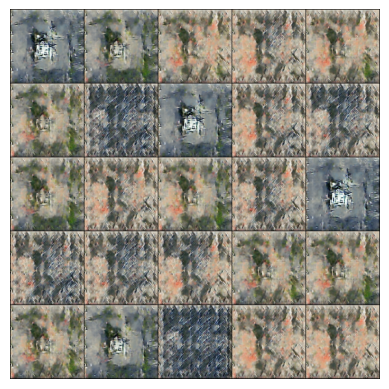

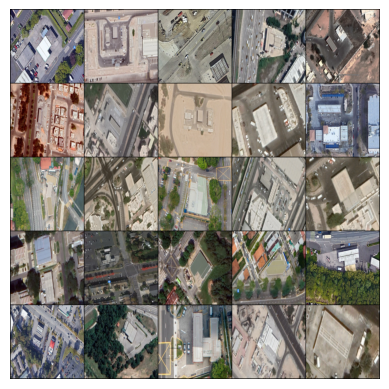

 43%|████████████████████████████████████                                                | 3/7 [00:35<00:46, 11.61s/it]

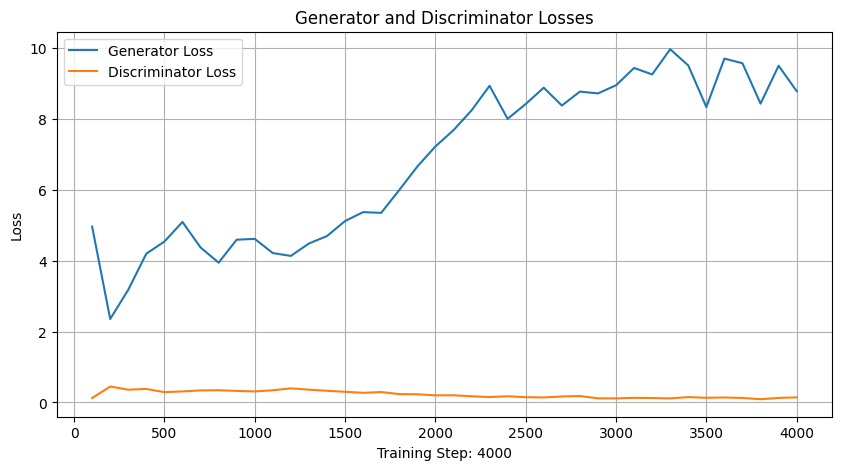

Step 4000: Generator loss: 8.778973571024835, discriminator loss: 0.14415195878595113


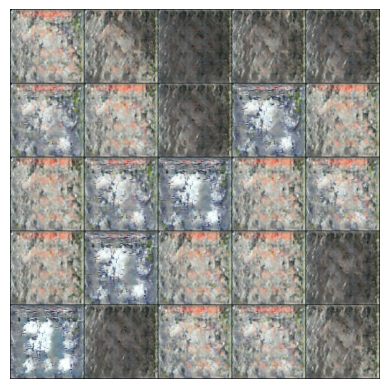

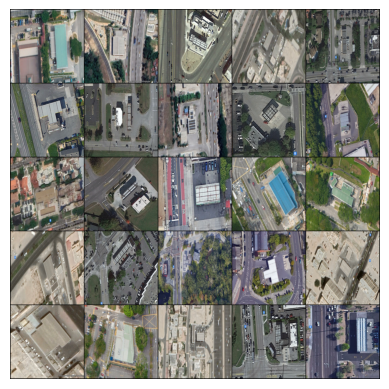

 71%|████████████████████████████████████████████████████████████                        | 5/7 [00:54<00:20, 10.45s/it]

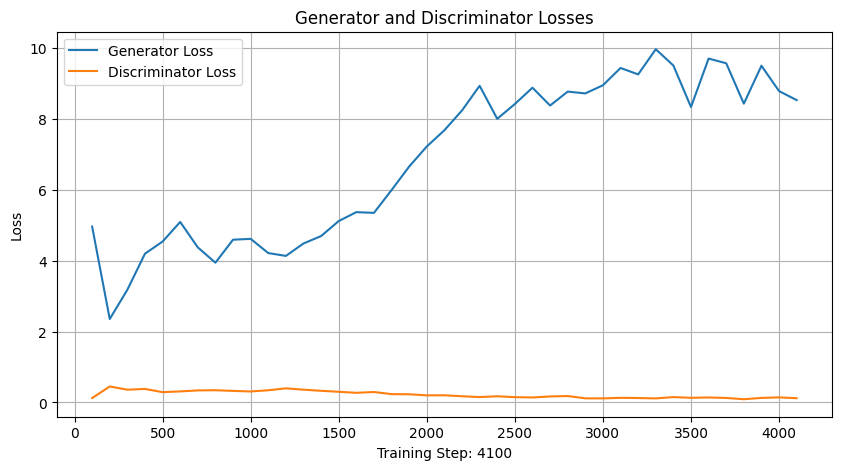

Step 4100: Generator loss: 8.525258710384369, discriminator loss: 0.1206678808038123


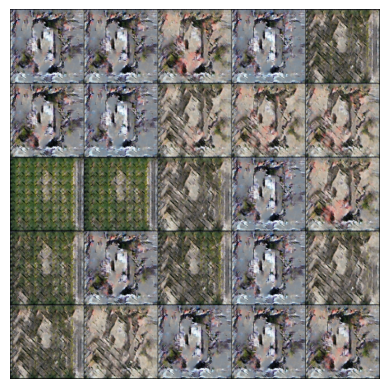

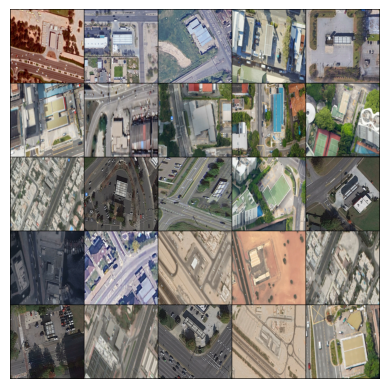

  0%|                                                                                            | 0/7 [00:00<?, ?it/s]

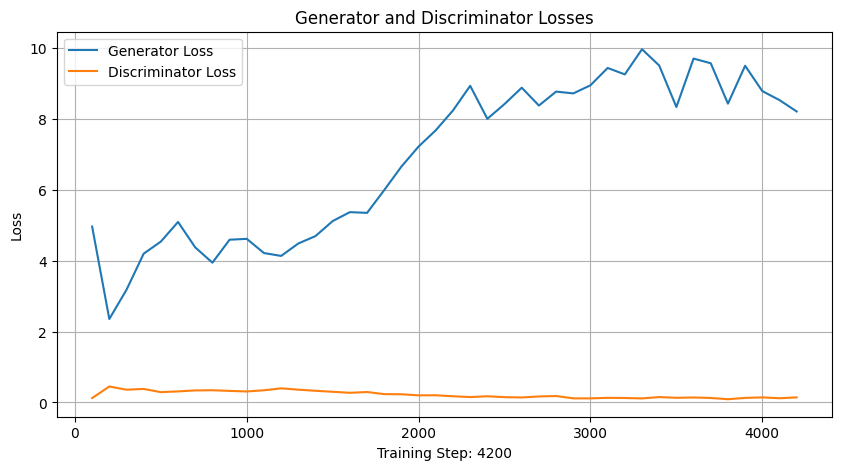

Step 4200: Generator loss: 8.204571823477744, discriminator loss: 0.14360063882777468


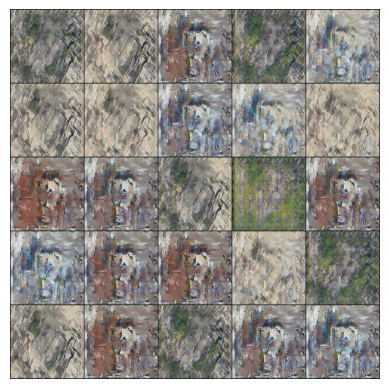

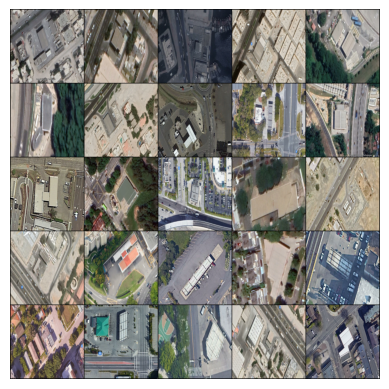

 29%|████████████████████████                                                            | 2/7 [00:25<01:02, 12.42s/it]

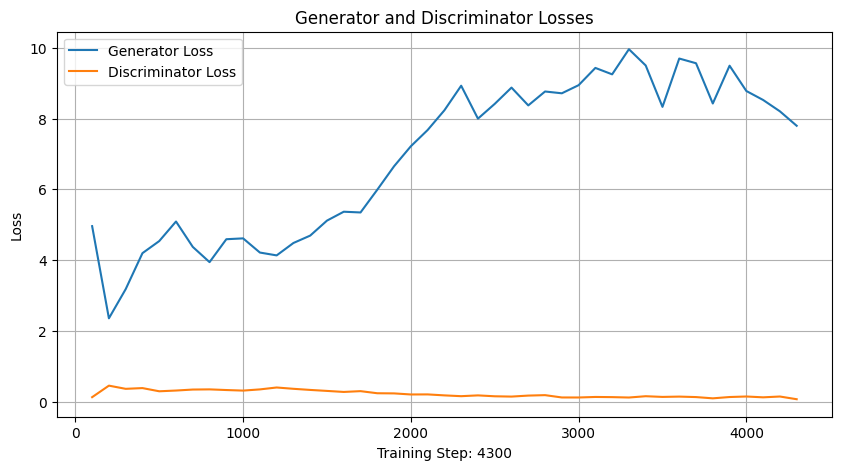

Step 4300: Generator loss: 7.795936713218689, discriminator loss: 0.06717283399309963


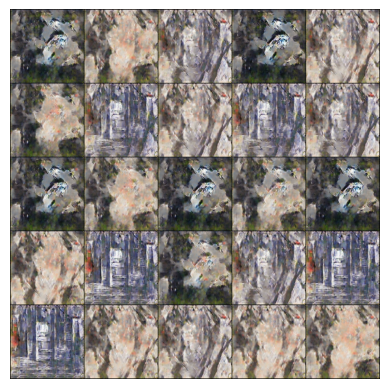

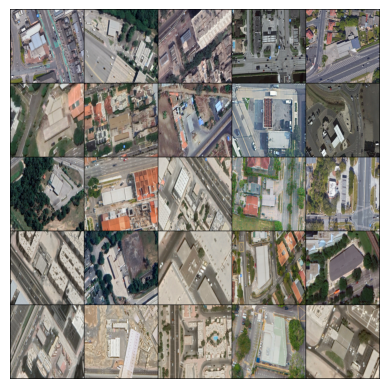

 57%|████████████████████████████████████████████████                                    | 4/7 [00:47<00:33, 11.18s/it]

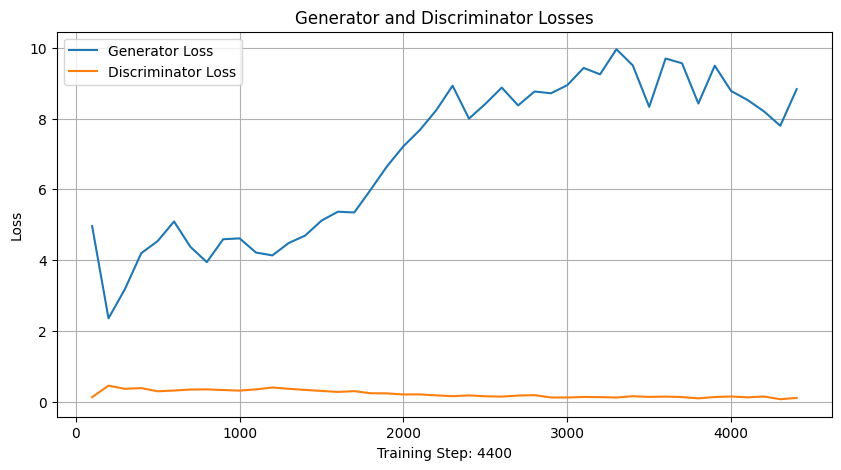

Step 4400: Generator loss: 8.832106320858001, discriminator loss: 0.10414431537268683


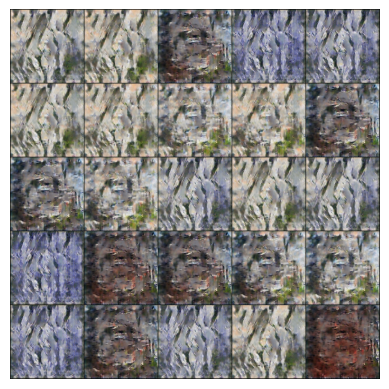

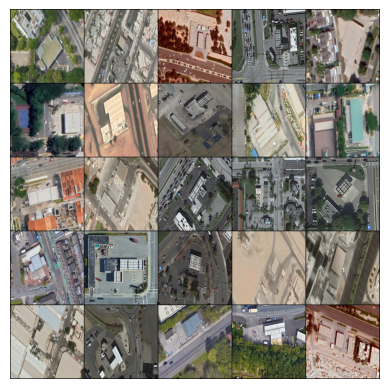

 86%|████████████████████████████████████████████████████████████████████████            | 6/7 [01:14<00:12, 12.42s/it]

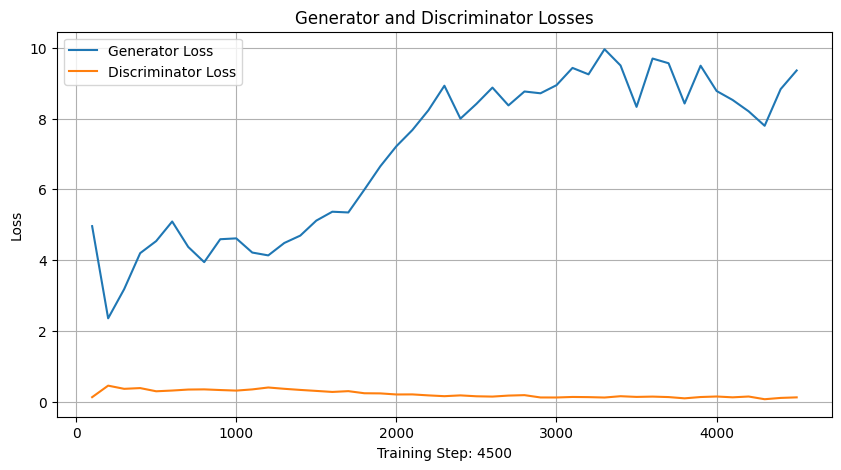

Step 4500: Generator loss: 9.359487528800964, discriminator loss: 0.119618563989643


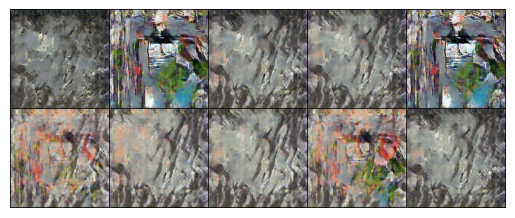

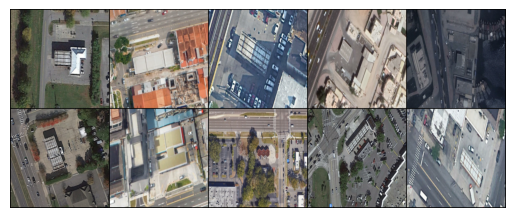

 14%|████████████                                                                        | 1/7 [00:13<01:18, 13.15s/it]

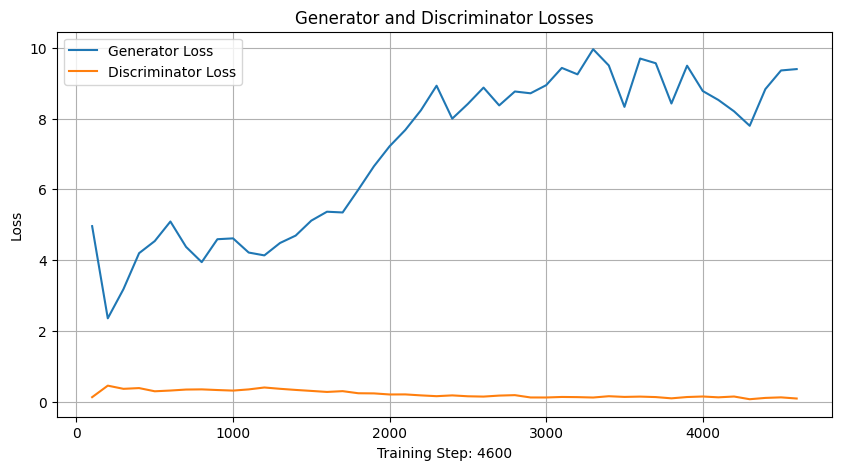

Step 4600: Generator loss: 9.398270248174667, discriminator loss: 0.08716426886618138


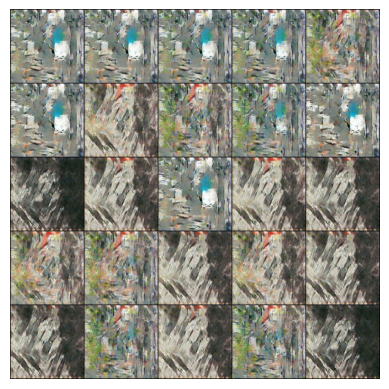

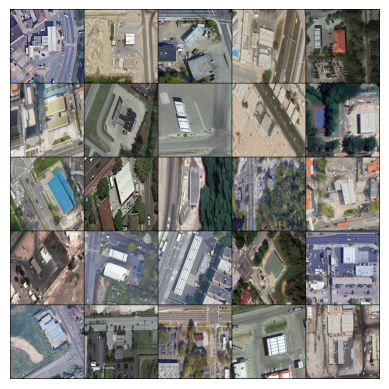

 43%|████████████████████████████████████                                                | 3/7 [00:34<00:44, 11.20s/it]

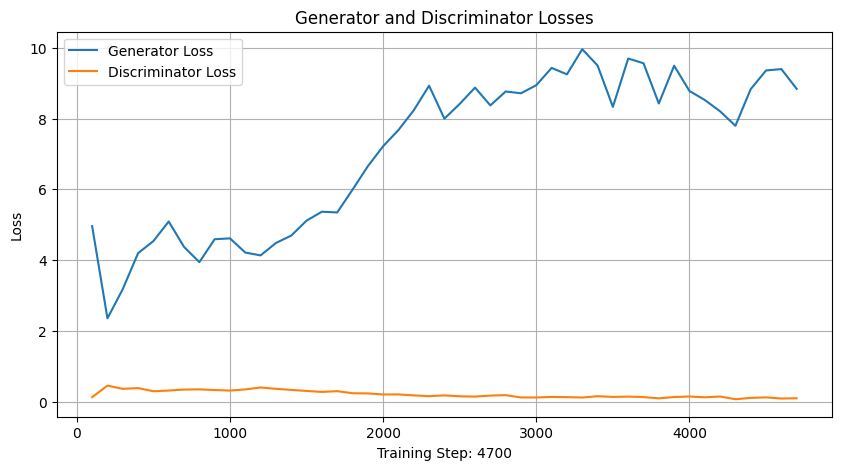

Step 4700: Generator loss: 8.840090598538518, discriminator loss: 0.09456133988918737


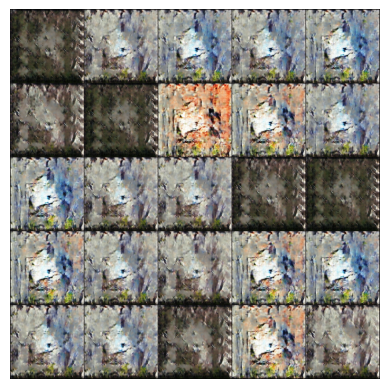

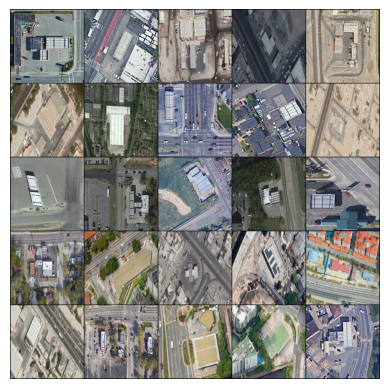

 71%|████████████████████████████████████████████████████████████                        | 5/7 [01:00<00:24, 12.12s/it]

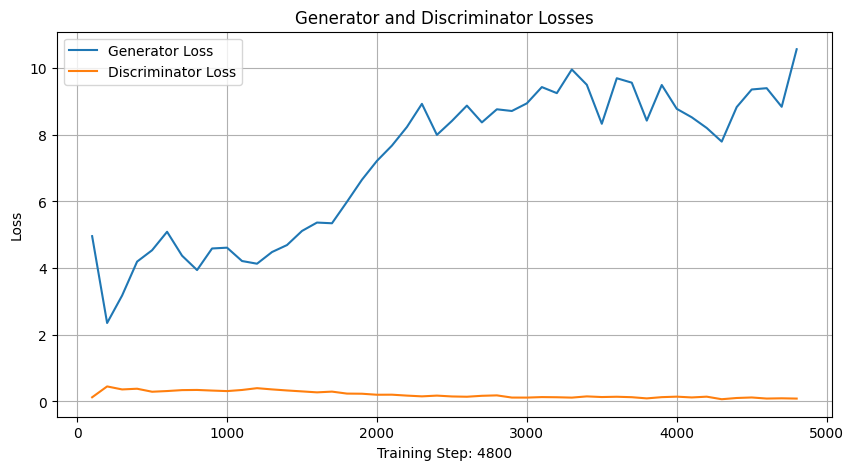

Step 4800: Generator loss: 10.567109819054604, discriminator loss: 0.08631651557167061


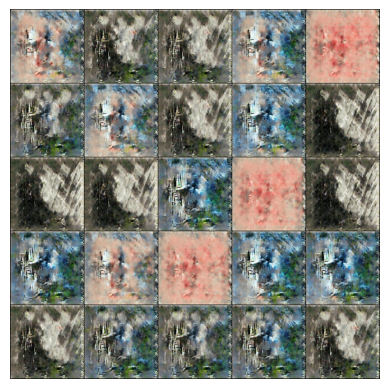

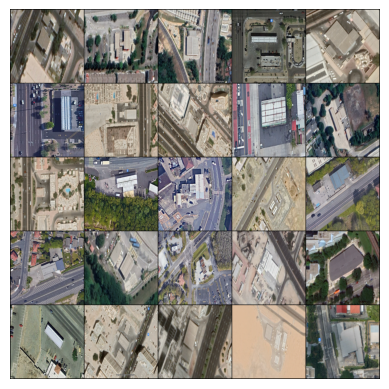

  0%|                                                                                            | 0/7 [00:00<?, ?it/s]

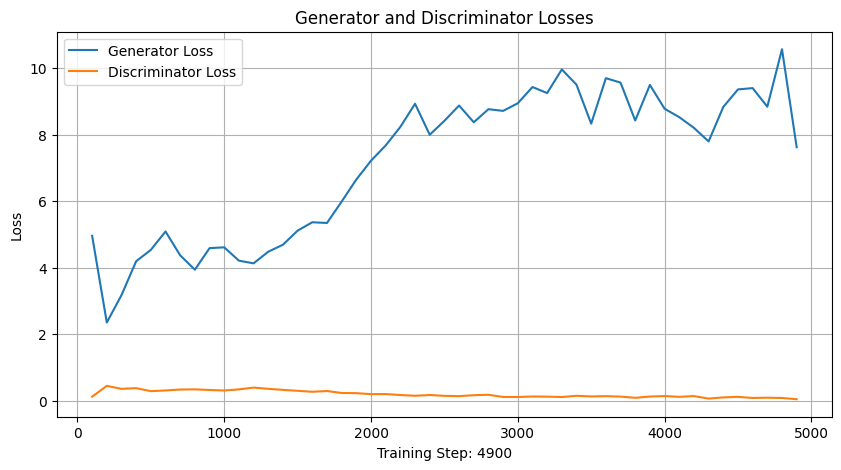

Step 4900: Generator loss: 7.6228398418426515, discriminator loss: 0.04917529347352684


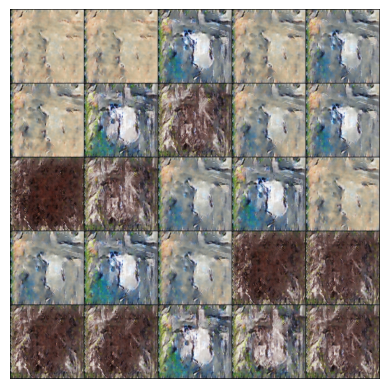

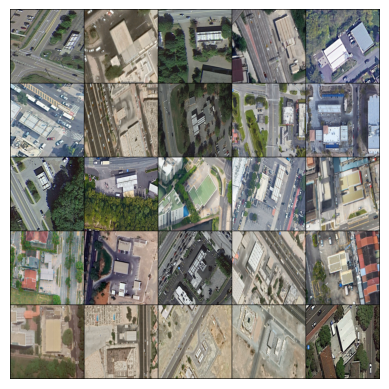

 29%|████████████████████████                                                            | 2/7 [00:26<01:05, 13.01s/it]

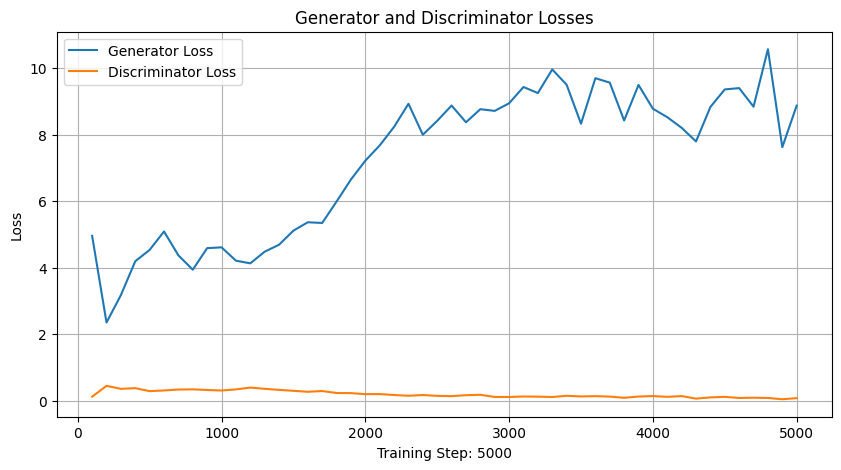

Step 5000: Generator loss: 8.871607959270477, discriminator loss: 0.08109979183471296


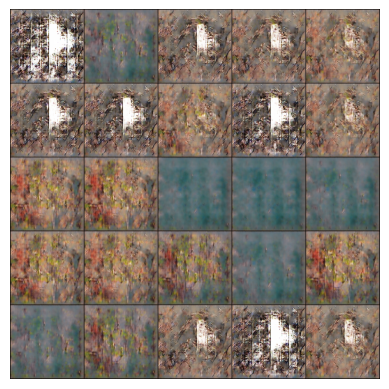

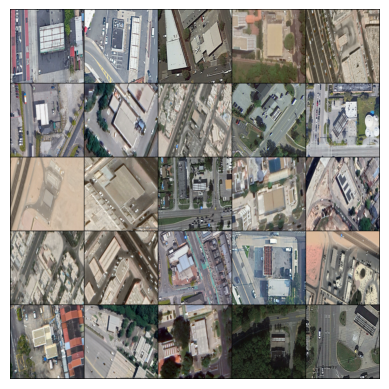

 57%|████████████████████████████████████████████████                                    | 4/7 [00:42<00:31, 10.35s/it]

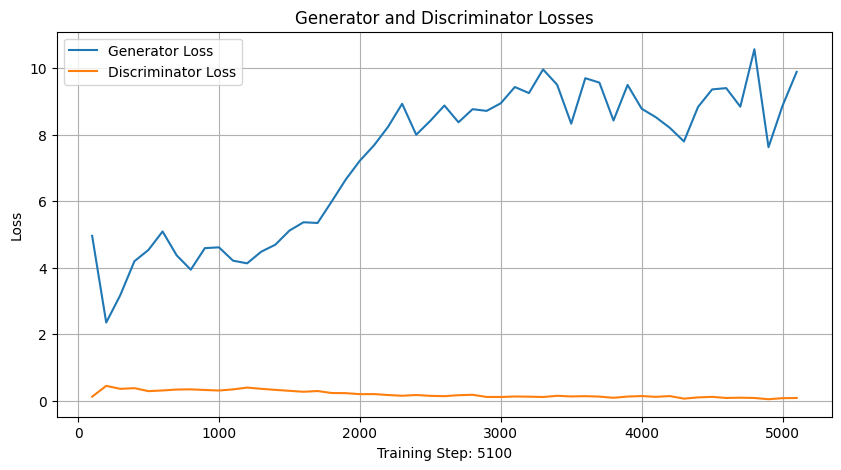

Step 5100: Generator loss: 9.886584632396698, discriminator loss: 0.08579219750128686


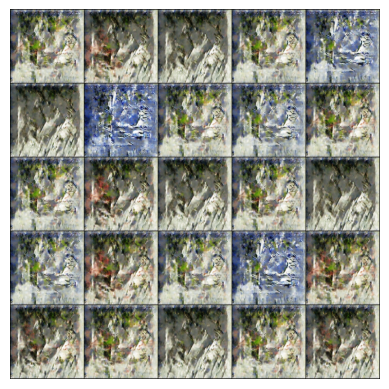

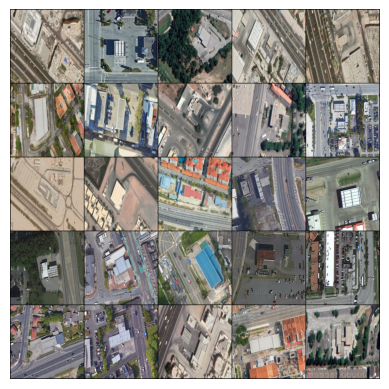

 86%|████████████████████████████████████████████████████████████████████████            | 6/7 [01:07<00:10, 10.62s/it]

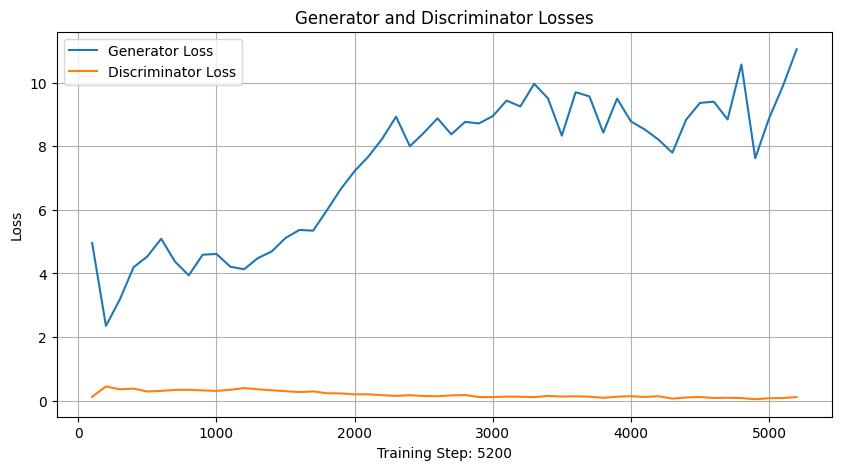

Step 5200: Generator loss: 11.046127262413501, discriminator loss: 0.11958488613483496


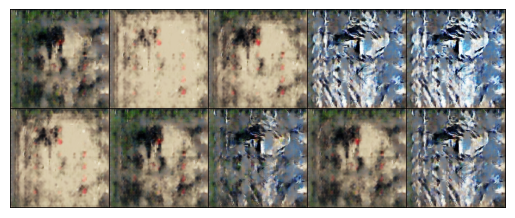

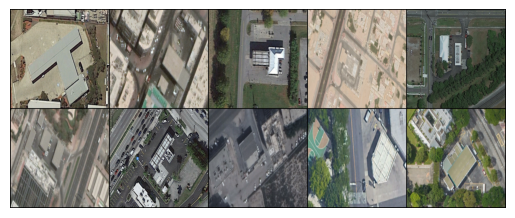

 14%|████████████                                                                        | 1/7 [00:16<01:38, 16.43s/it]

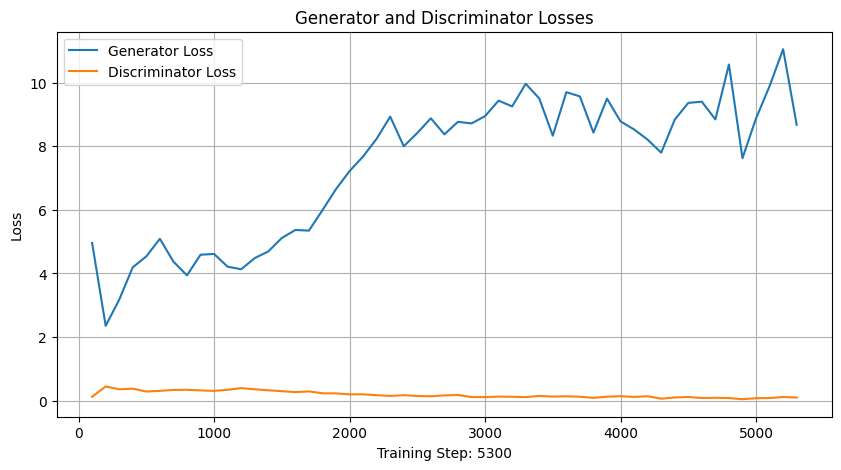

Step 5300: Generator loss: 8.672432552576065, discriminator loss: 0.10112631913274527


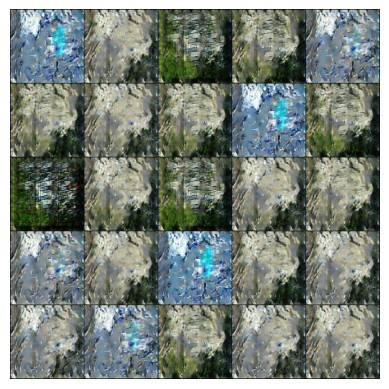

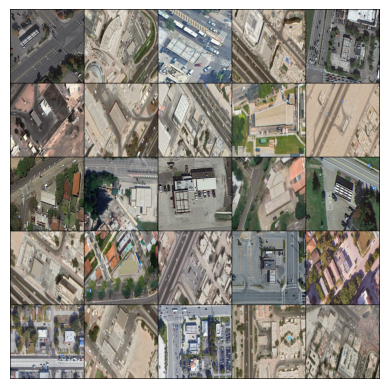

 43%|████████████████████████████████████                                                | 3/7 [00:35<00:46, 11.60s/it]

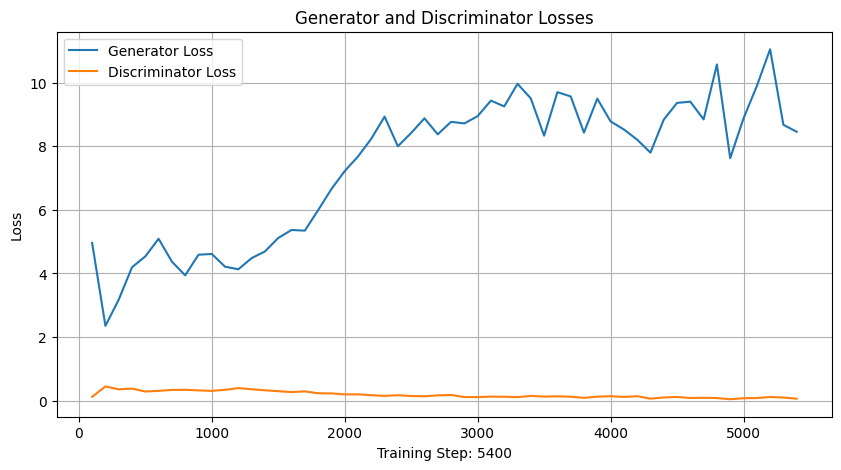

Step 5400: Generator loss: 8.451854858398438, discriminator loss: 0.06607792646158486


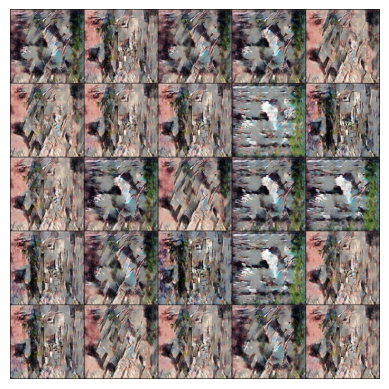

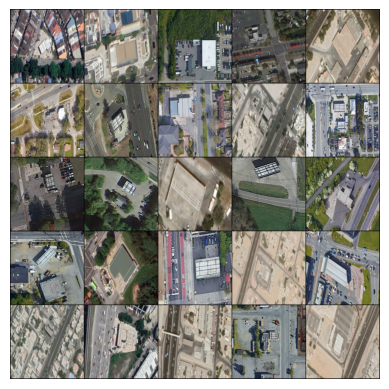

 71%|████████████████████████████████████████████████████████████                        | 5/7 [00:54<00:20, 10.27s/it]

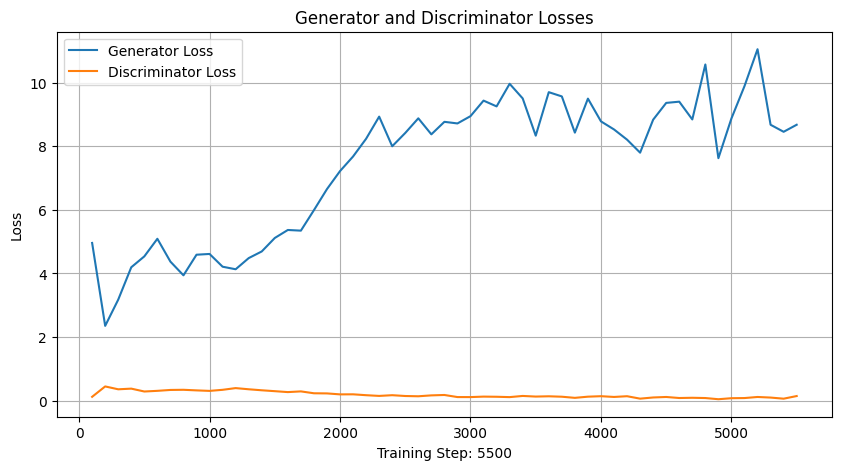

Step 5500: Generator loss: 8.67297064465005, discriminator loss: 0.14896277176216244


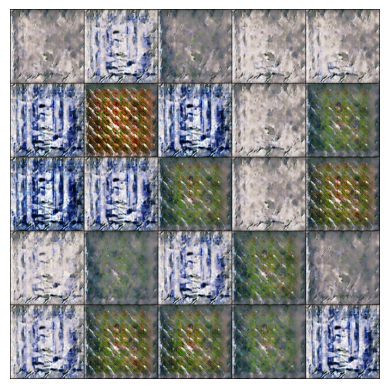

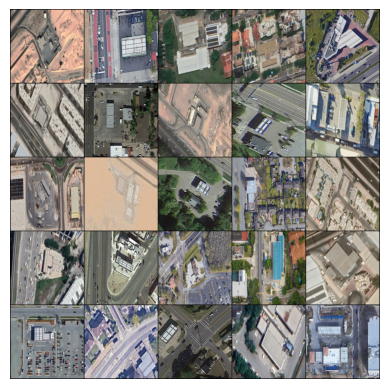

  0%|                                                                                            | 0/7 [00:00<?, ?it/s]

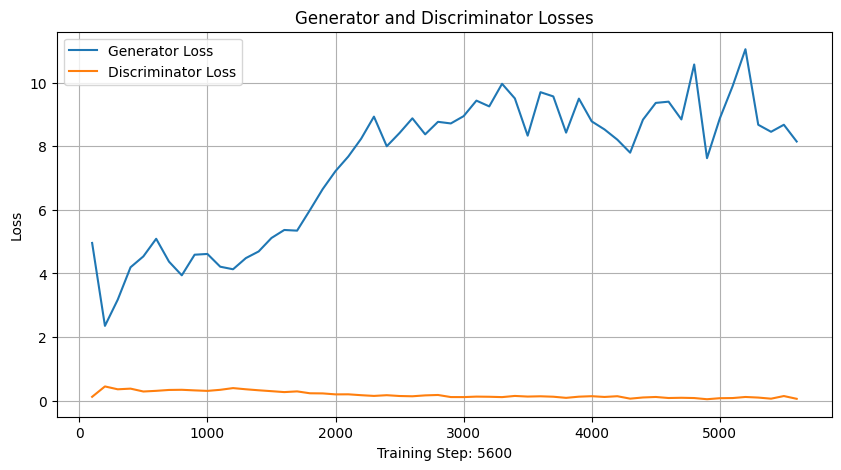

Step 5600: Generator loss: 8.146459896564483, discriminator loss: 0.06215457545826211


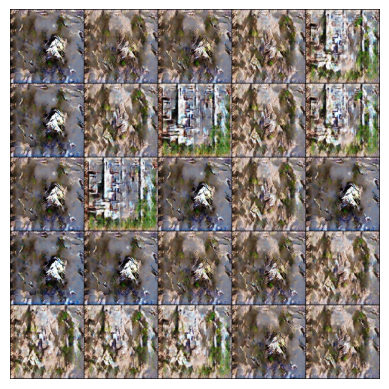

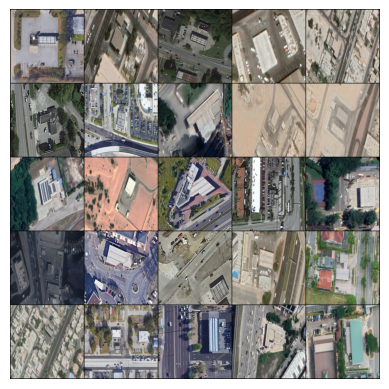

 29%|████████████████████████                                                            | 2/7 [00:24<00:58, 11.80s/it]

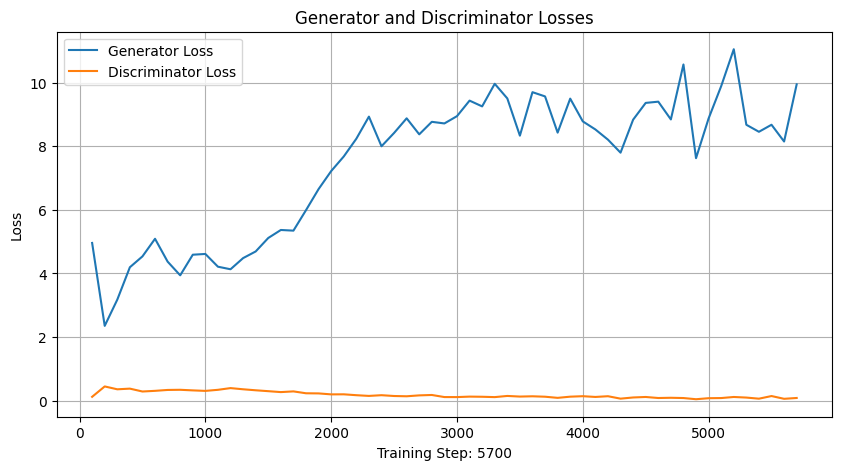

Step 5700: Generator loss: 9.941853716373444, discriminator loss: 0.08827088563004509


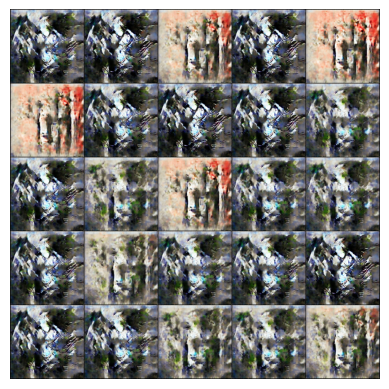

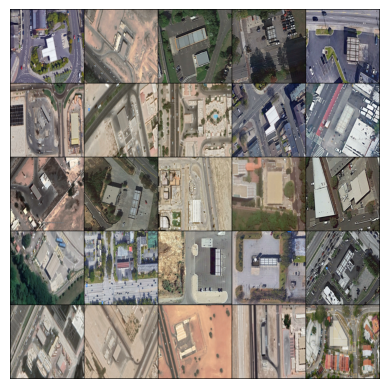

 57%|████████████████████████████████████████████████                                    | 4/7 [00:50<00:38, 12.82s/it]

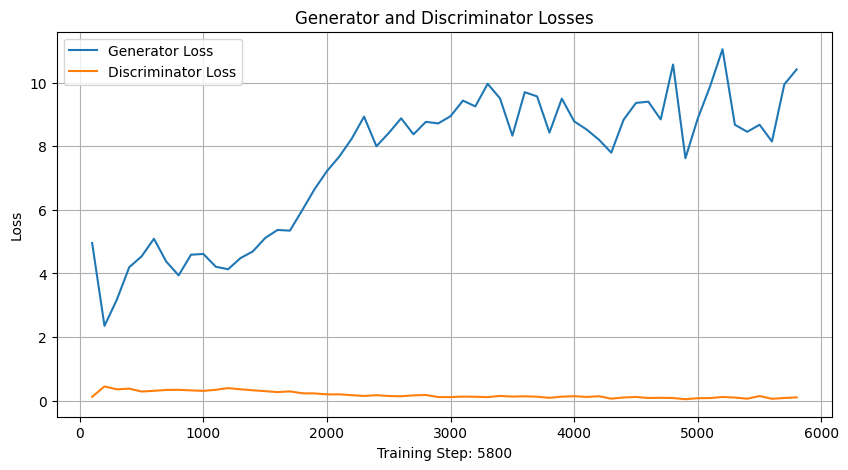

Step 5800: Generator loss: 10.41222634471953, discriminator loss: 0.10817870362428948


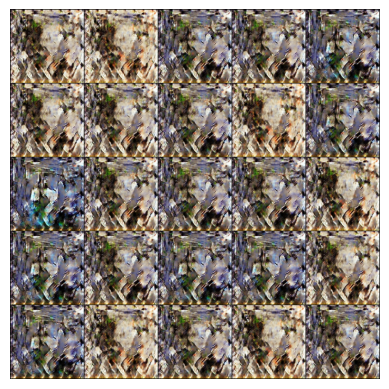

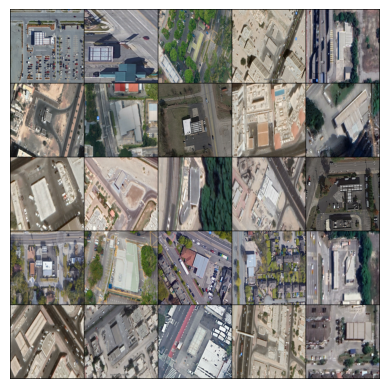

 86%|████████████████████████████████████████████████████████████████████████            | 6/7 [01:08<00:10, 10.98s/it]

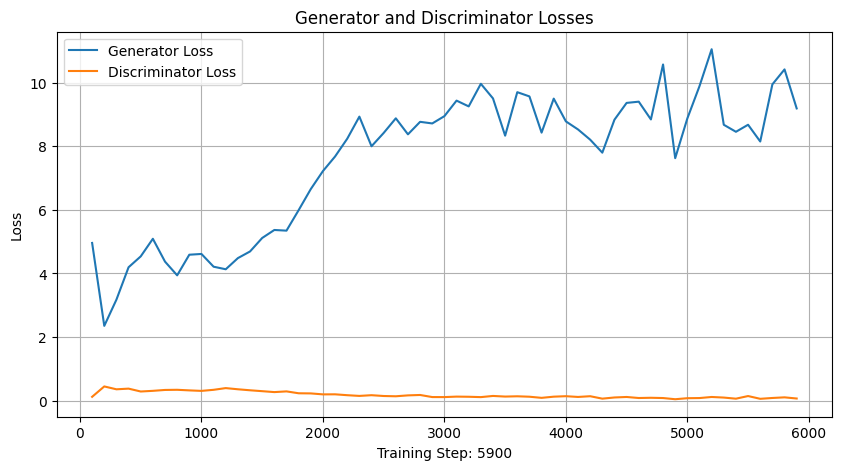

Step 5900: Generator loss: 9.18608249247074, discriminator loss: 0.07149617411429063


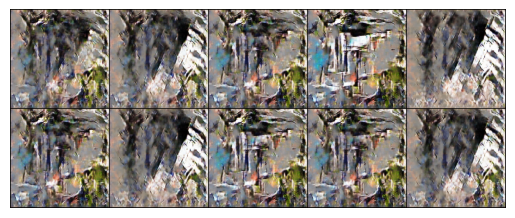

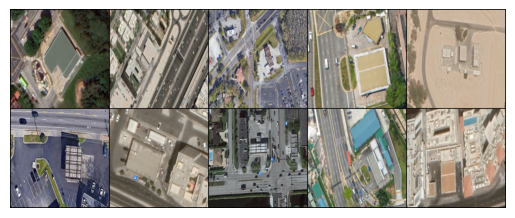

 14%|████████████                                                                        | 1/7 [00:13<01:19, 13.19s/it]

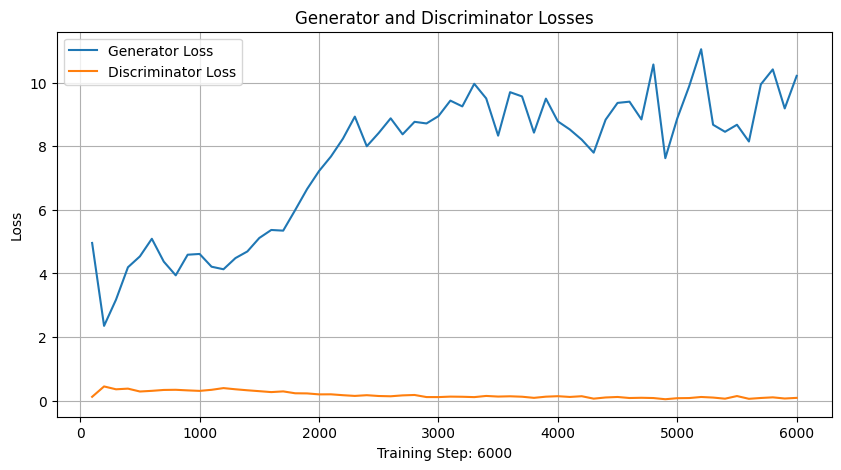

Step 6000: Generator loss: 10.208807530552148, discriminator loss: 0.0914785239705816


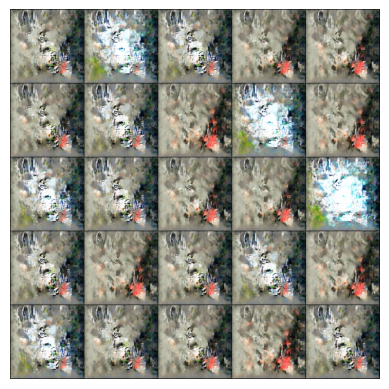

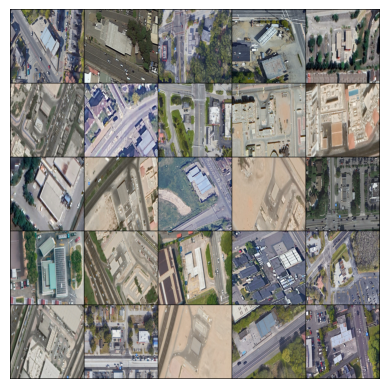

 43%|████████████████████████████████████                                                | 3/7 [00:36<00:45, 11.48s/it]

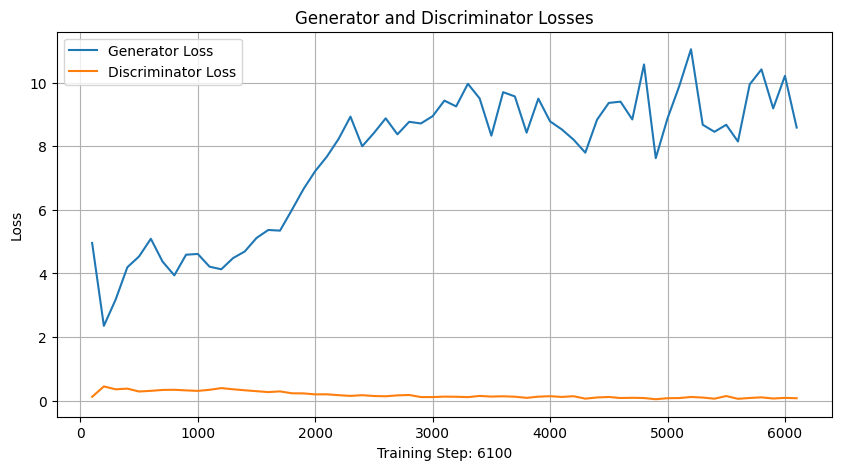

Step 6100: Generator loss: 8.584148676991463, discriminator loss: 0.0799392225802876


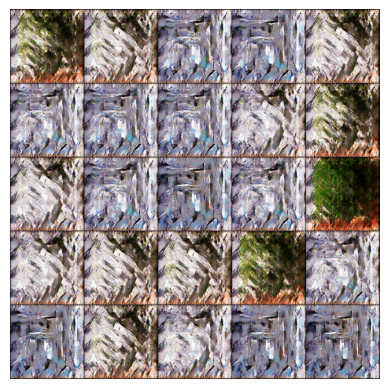

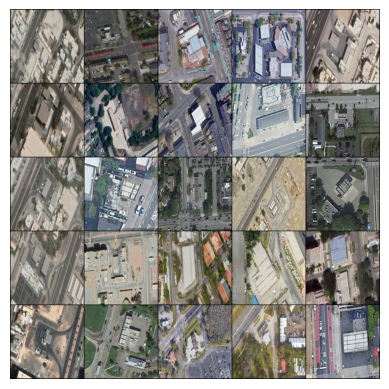

 71%|████████████████████████████████████████████████████████████                        | 5/7 [01:00<00:24, 12.12s/it]

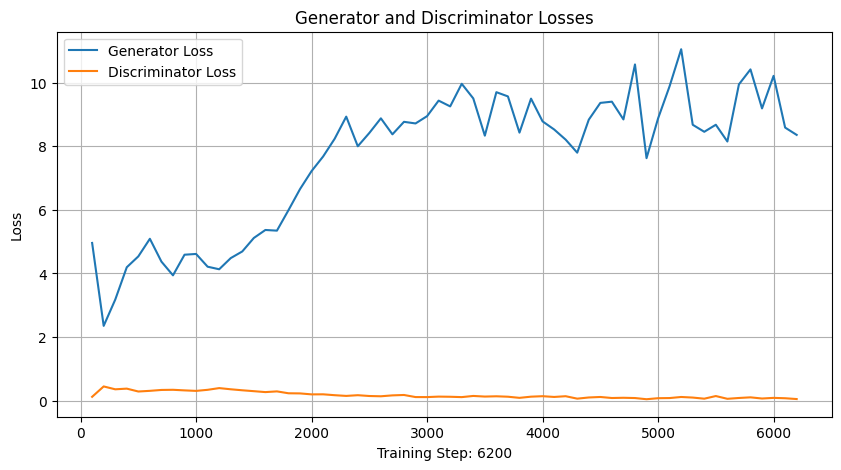

Step 6200: Generator loss: 8.354049335718155, discriminator loss: 0.054434268970508126


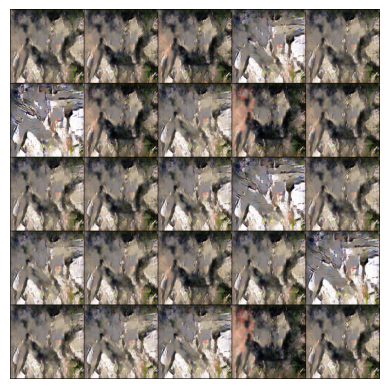

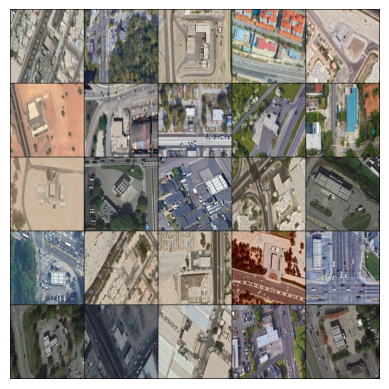

  0%|                                                                                            | 0/7 [00:00<?, ?it/s]

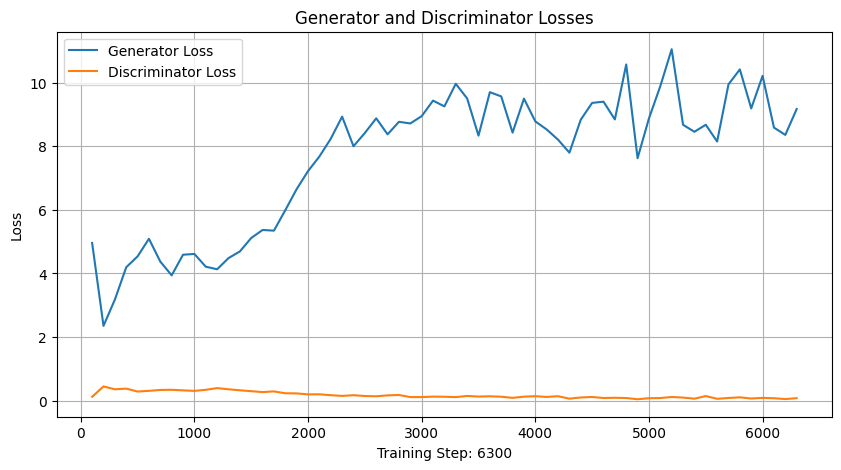

Step 6300: Generator loss: 9.166579203233123, discriminator loss: 0.0822411261452362


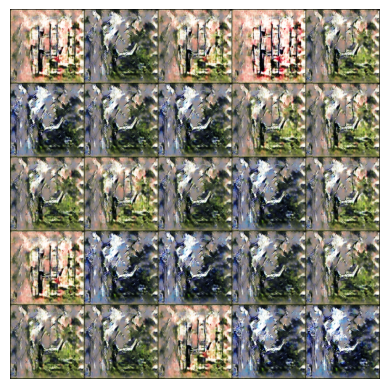

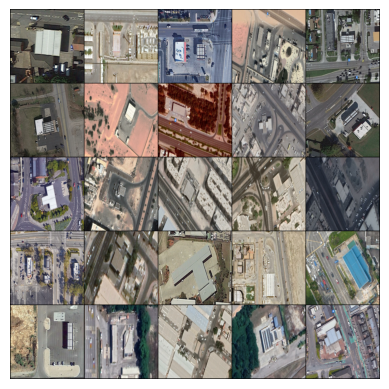

 29%|████████████████████████                                                            | 2/7 [00:21<00:53, 10.73s/it]

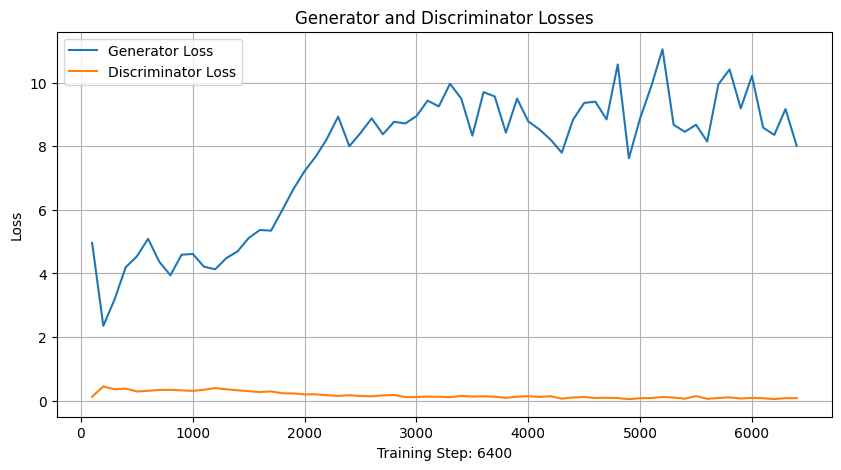

Step 6400: Generator loss: 8.010141210015863, discriminator loss: 0.08216278107604012


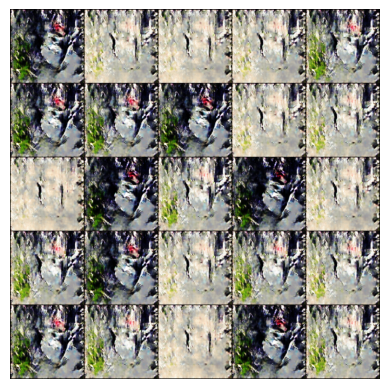

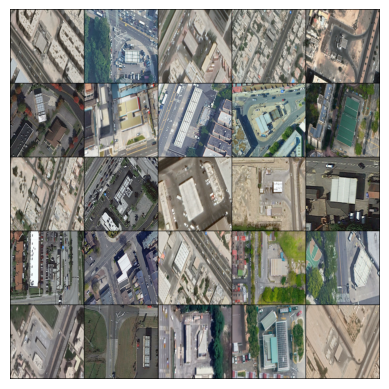

 57%|████████████████████████████████████████████████                                    | 4/7 [00:45<00:34, 11.50s/it]

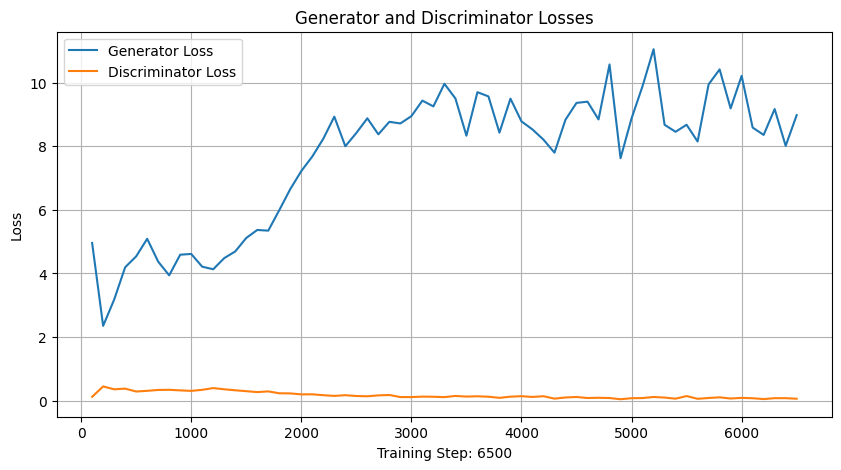

Step 6500: Generator loss: 8.97488653600216, discriminator loss: 0.06456073018256575


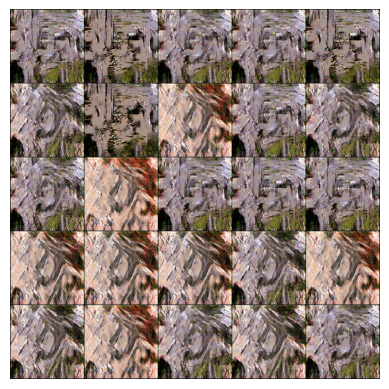

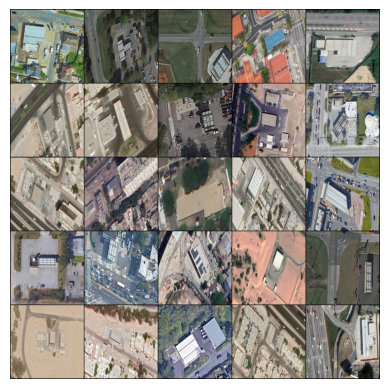

 86%|████████████████████████████████████████████████████████████████████████            | 6/7 [01:14<00:11, 11.59s/it]

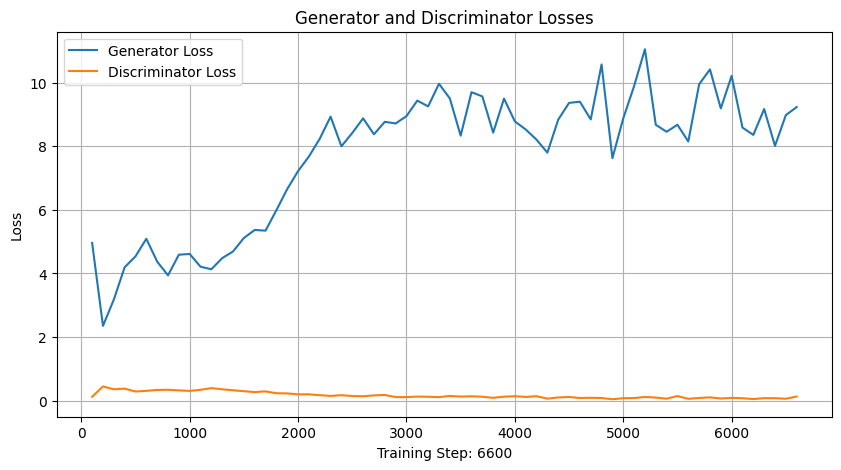

Step 6600: Generator loss: 9.228580217785202, discriminator loss: 0.13377459650073434


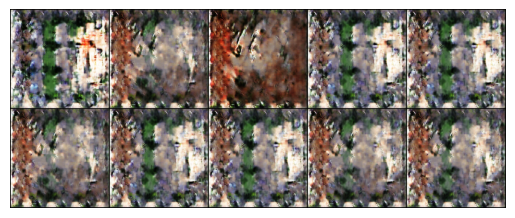

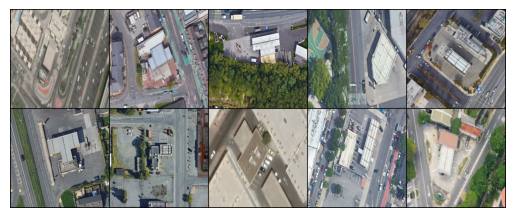

 14%|████████████                                                                        | 1/7 [00:13<01:22, 13.73s/it]

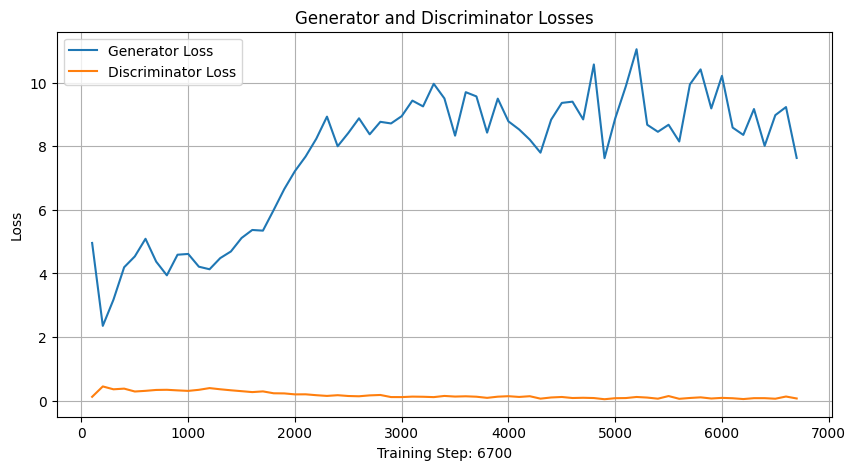

Step 6700: Generator loss: 7.629957402125001, discriminator loss: 0.0725650879368186


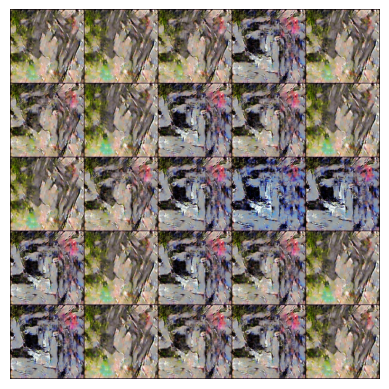

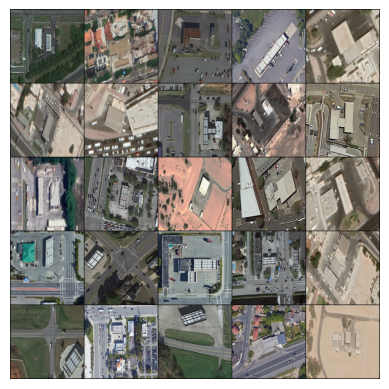

 43%|████████████████████████████████████                                                | 3/7 [00:31<00:40, 10.09s/it]

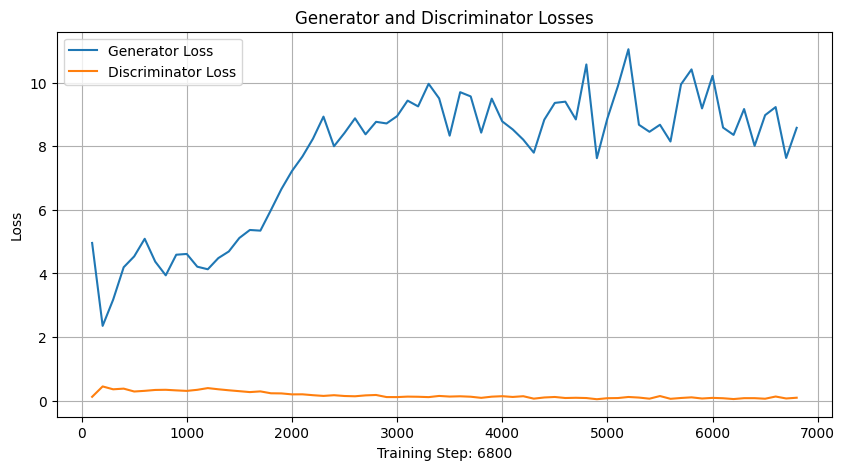

Step 6800: Generator loss: 8.576564188599587, discriminator loss: 0.09606654956762213


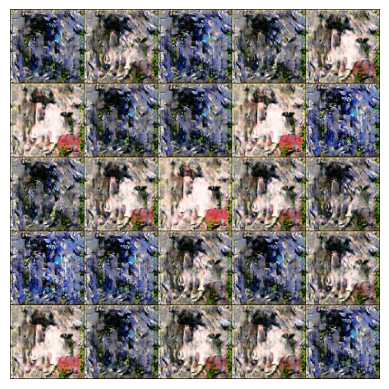

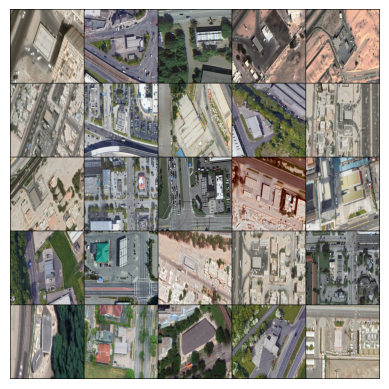

 71%|████████████████████████████████████████████████████████████                        | 5/7 [00:51<00:19,  9.83s/it]

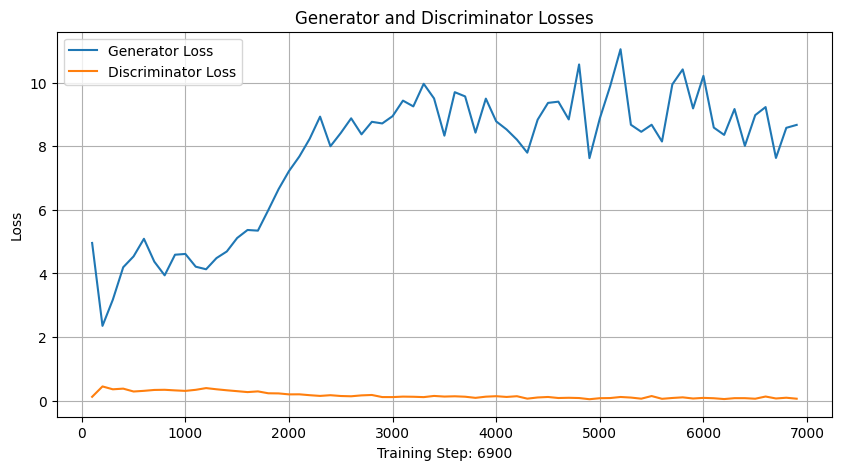

Step 6900: Generator loss: 8.668663682043553, discriminator loss: 0.06520771627314388


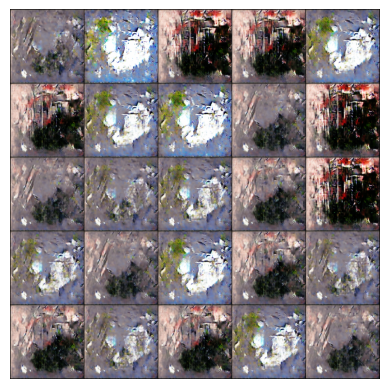

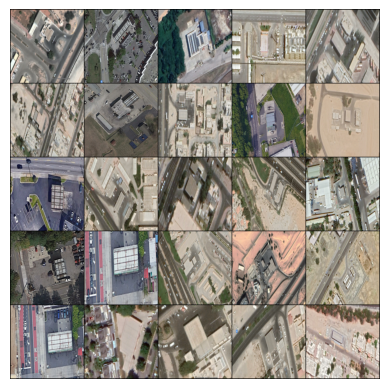

100%|████████████████████████████████████████████████████████████████████████████████████| 7/7 [01:11<00:00, 10.25s/it]


Time taken: 72617.96 seconds


In [15]:
current_step = 0
total_generator_loss = 0
total_discriminator_loss = 0

generator_losses = [] 
discriminator_losses = [] 
steps = [] 

import time
start_time = time.time()

for epoch in range(n_epochs):
    for real in tqdm(dataloader):
        batch_size = len(real)
        real = real.to(device)

        # Discriminator 
        disc_opt.zero_grad()
        fake_noise = get_noise(batch_size, z_dim, device=device)
        fake = gen(fake_noise)
        disc_fake_pred = disc(fake.detach())
        disc_fake_loss = criterion(disc_fake_pred, torch.zeros_like(disc_fake_pred))
        disc_real_pred = disc(real)
        disc_real_loss = criterion(disc_real_pred, torch.ones_like(disc_real_pred))
        disc_loss = (disc_fake_loss + disc_real_loss) / 2
        
        total_discriminator_loss += disc_loss.item()
        disc_loss.backward(retain_graph=True)
        disc_opt.step()

        # Generator 
        gen_opt.zero_grad()
        fake_noise_2 = get_noise(batch_size, z_dim, device=device)
        fake_2 = gen(fake_noise_2)
        disc_fake_pred = disc(fake_2)
        gen_loss = criterion(disc_fake_pred, torch.ones_like(disc_fake_pred))
        gen_loss.backward()
        gen_opt.step()

        total_generator_loss += gen_loss.item() 

        if current_step % display_step == 0 and current_step > 0:
            mean_discriminator_loss = total_discriminator_loss / display_step 
            mean_generator_loss = total_generator_loss / display_step 
            
            generator_losses.append(mean_generator_loss)
            discriminator_losses.append(mean_discriminator_loss)
            steps.append(current_step)
            
            plt.figure(figsize=(10, 5))
            plt.plot(steps, generator_losses, label='Generator Loss')
            plt.plot(steps, discriminator_losses, label='Discriminator Loss')
            plt.xlabel(f'Training Step: {current_step}')
            plt.ylabel('Loss')
            plt.title('Generator and Discriminator Losses')
            plt.legend()
            plt.grid(True)
            plt.show()
            
            print(f"Step {current_step}: Generator loss: {mean_generator_loss}, discriminator loss: {mean_discriminator_loss}")
            fake_noise = get_noise(batch_size, z_dim, device)
            fake = gen(fake_noise)
            display_tensor_images(fake)
            display_tensor_images(real)
            total_discriminator_loss = 0
            total_generator_loss = 0
        current_step += 1
        
end_time = time.time()

elapsed_time = end_time - start_time
print(f"Time taken: {elapsed_time:.2f} seconds")

In [16]:
save_checkpoints(gen, disc, gen_opt, disc_opt, gen_loss, disc_loss, f'{DATA_PATHS["checkpoints"]}/checkpoint_61000.pt')